## Trabajo Práctico ALC 2c2026 - Calibración y Pose de la Cámara

### Grupo: CHORIPÁN

### Integrantes
| Integrante | LU |
|---|---|
| Fabian Gomez Laguna | 522/20 |
| Nicolas Sergio Aquino | 290/20 |
| Nicolas Pelayo | 774/22 |
| María del Rosario Chuit | 1063/24 |

---

Antes que nada importamos y definimos algunas funciones auxiliares que nos serán de utilidad.

In [111]:
import os
import numpy as np
import alc
import pandas as pd
import cv2
from matplotlib import pyplot as plt

# Guardamos los gráficos como JPEG en lugar de PNG para que la notebook pese menos
%config InlineBackend.figure_format = 'jpeg'

# Para imprimir con menos decimales y con 0s cuando el num esté muy cerca a 0
np.set_printoptions(precision=4, suppress=True)

In [112]:
# DIR_DATOS es la carpeta que contiene calib/, futbol/, etc.
DIR_DATOS = '.'

DIR_CALIB_3D = os.path.join(DIR_DATOS, 'calib', '3d')              # Ejercicio 2
DIR_CALIB_COPLANAR = os.path.join(DIR_DATOS, 'calib', 'coplanar')  # Ejercicio 3
DIR_FUTBOL = os.path.join(DIR_DATOS, 'futbol')                     # Ejercicio 4
DIR_SALGUERO = os.path.join(DIR_DATOS, 'salguero')                 # Ejercicio 5
DIR_GS_DATASET = os.path.join(DIR_DATOS, 'gs_dataset')             # Ejercicio 5.c (Frames)
DIR_HELI = os.path.join(DIR_DATOS, 'heli')                         # Ejercicio 6

In [113]:
def leer_imagen(path):
    """
    Lee una imagen con cv2 y la devuelve en RGB (por default es BGR y eso invierte los colores).
    
    path: ruta al archivo 
    Devuelve la imagen en RGB `array(alto, ancho, 3)`
    """
    return cv2.imread(path)[:, :, ::-1]


def mostrar_puntos(img, pts, etiquetas=None, pts_proyectados=None, titulo='', figsize=(12, 8)):
    """
    Dibuja sobre `img` los puntos `pts` observados (amarillo) y lo imprime en el notebook
    opcionalmente recibe los puntos proyectados `pts_proyectados` para comparar visualmente (rojo)

    Parametros:
        img: imagen
        pts: array de con n puntos observados (u, v)
        etiquetas: textos para cada punto uno de los n pts
        pts_proyectados: array (m, 2) con los puntos proyectados (u, v) 
        titulo: título del gráfico
        figsize: tamaño de la figura
    """
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.scatter(pts[:, 0], pts[:, 1], s=45, c='yellow', edgecolors='black', label='Originales', zorder=4)
    if pts_proyectados is not None:
        plt.scatter(pts_proyectados[:, 0], pts_proyectados[:, 1], s=30, c='red',
                    edgecolors='black', label='Proyectados', zorder=5)
        plt.legend()
    if etiquetas is not None:
        for (u, v), etiqueta in zip(pts, etiquetas):
            plt.text(u + 12, v - 12, str(etiqueta), color='white', backgroundcolor='black', fontsize=8)
    plt.title(titulo)
    plt.show()


---

### Ejercicio 1 - DLT ecuaciones formales

**a) Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?**


Se tiene que $Q \in \mathbb{R}^{2n \times 12}$, por lo que representa una transformación lineal:

$$
Q:\mathbb{R}^{12}\longrightarrow\mathbb{R}^{2n}
$$

Para resolver el sistema homogéneo $Qm=0$ y obtener una solución no nula única salvo un factor de escala, necesitamos que el núcleo de $Q$ tenga dimensión 1:

$$
\dim(\operatorname{Nu}(Q))=1
$$

Como la dimensión de la imagen coincide con el rango:

$$
\dim(\operatorname{Im}(Q))=\operatorname{rg}(Q)
$$

Entonces, por el teorema de la dimensión tenemos que:

$$
\dim(\mathbb{R}^{12})=\dim(\operatorname{Nu}(Q))+\dim(\operatorname{Im}(Q))
$$

Entonces:

$$
12=1+\operatorname{rg}(Q)
\Longrightarrow \operatorname{rg}(Q)=11
$$

Por lo tanto, necesitamos que $Q$ tenga rango 11 para obtener una solución no nula única salvo escala.

Respecto a la cantidad de puntos necesarios podemos decir que como cada correspondencia entre un punto 3D y uno 2D genera dos filas de $Q$, y sabemos que:

$$
\operatorname{rg}(Q)\leq\min(2n,12)
$$

Como necesitamos que $Q$ tenga rango 11:

$$
11\leq 2n
\Longrightarrow n\geq\frac{11}{2}
\Longrightarrow n\geq6
$$

Entonces, se necesitan al menos 6 puntos.

Por último, la condición que deben cumplir los puntos es que no deben ser todos coplanares, pues si lo son el rango de $Q$ va a ser menor a 11, y la solución no va a ser única salvo un factor escala . Por ejemplo, si pertenecen al plano $W=0$, las columnas de $Q$ que contienen $W_i$, $-u_iW_i$ y $-v_iW_i$ son nulas.

Entonces:

$$
\operatorname{rg}(Q)\leq9<11
$$

Y por el teorema de la dimensión tenemos que:

$$
\dim(\operatorname{Nu}(Q))=12-\operatorname{rg}(Q)\geq3
$$

Por lo tanto, el núcleo deja de tener dimensión 1 y la solución deja de ser única salvo un factor escala.

En conclusión, para poder aplicar DLT y conseguir una solución única salvo un factor escala, se necesita que $\operatorname{rg}(Q)=11$, un mínimo de 6 correspondencias entre puntos 3D y 2D, y que los puntos no sean todos coplanares.



**b) Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.**

Nosotros buscamos resolver el sistema homogéneo $Qm=0$. Sin embargo, cuando trabajamos con datos reales, por ejemplo debido a errores de localización de puntos, puede ocurrir que no exista un vector no nulo que cumpla $Qm=0$.

Por eso buscamos un vector $\mathbf{m}$ que minimice la norma cuadrada de $Qm$, con $\|m\|_2=1$ para evitar la solución trivial $m=0$.

Por lo tanto, vamos a resolver:

$$
\min_{\|m\|_2=1}\|Qm\|_2^2
$$

Partimos de realizar la descomposción SVD de $Q$, entonces:

$$
Q=U\Sigma V^T
$$

Como buscamos $\mathbf{m}$ que minimice $\|Qm\|_2^2$, sujeto a $\|m\|_2=1$ , reemplazando por la SVD, tenemos que:

$$
\|Qm\|_2^2
=\|U\Sigma V^Tm\|_2^2
=\|\Sigma V^Tm\|_2^2
$$

La última igualdad se cumple porque $U$ es ortogonal y, por lo tanto, conserva la norma euclídea.

Si tomamos:

$$
x=V^Tm
$$

Como $Q\in\mathbb{R}^{2n\times12}$ y consideramos $n\geq6$, tenemos que $\min(2n,12)=12$. Por lo tanto, su descomposición SVD tiene 12 valores singulares, contando los que puedan ser nulos.

Entonces, tenemos que:

$$
\|\Sigma x\|_2^2
=
\left\|
\begin{pmatrix}
\sigma_1 & & 0\\
& \ddots &\\
0 & & \sigma_{12}
\end{pmatrix}
\begin{pmatrix}
x_1\\
\vdots\\
x_{12}
\end{pmatrix}
\right\|_2^2
$$
Para simplificar la notación, representamos únicamente la parte diagonal de  $\Sigma$, ya que las filas restantes son nulas y no afectan el cálculo de la norma.
 
Por lo tanto:

$$
\|\Sigma x\|_2^2
=
\left\|
\begin{pmatrix}
\sigma_1x_1\\
\vdots\\
\sigma_{12}x_{12}
\end{pmatrix}
\right\|_2^2
=
\sum_{i=1}^{12}\sigma_i^2x_i^2
$$

Como los valores singulares están ordenados de mayor a menor:

$$
\sigma_1\geq\sigma_2\geq\cdots\geq\sigma_{12}\geq0
$$

Tenemos que:

$$
\sum_{i=1}^{12}\sigma_i^2x_i^2
\geq
\sigma_{12}^2\sum_{i=1}^{12}x_i^2
$$

Como $$\|x\|_2^2=\sum_{i=1}^{12}x_i^2$$
Veamos que $\|x\|_2^2=1$:

$$
\|x\|_2^2
=(V^Tm)^T(V^Tm)
$$

$$
=m^TVV^Tm
=m^TIm
=\|m\|_2^2=1
$$

Esto se cumple porque $V$ es ortogonal y porque impusimos $\|m\|_2=1$.

Entonces tenemos que:

$$
\sum_{i=1}^{12}\sigma_i^2x_i^2
\geq
\sigma_{12}^2\sum_{i=1}^{12}x_i^2
=\sigma_{12}^2
$$

Esta cota inferior se alcanza tomando el vector canónico $e_{12}$ , por lo que se tiene $x=e_{12}$ que cumple $\|x\|_2=1$.

Por lo tanto, el mínimo es $\sigma_{12}^2$.

Finalmente, despejamos $m$:

$$
x=V^Tm
$$

Como $V$ es ortogonal:

$$
Vx=VV^Tm=m
$$

Tomando $x=e_{12}$:

$$
m=Ve_{12}=v_{12}
$$

En conclusión, el mínimo de $\|Qm\|_2^2$, sujeto a $\|m\|_2=1$, se alcanza tomando como $m$ el vector singular derecho asociado al menor valor singular de $Q$, es decir, la última columna de $V$.



<hr style="border: none; border-top: 3px solid black;">

### Ejercicio 2 - Calibración con puntos 3D

**a) Implementar la función `obtenerQ3d(imgPts, objPts)` que devuelve la matriz $Q$ a partir de la ecuación 6.**

Cant. puntos 3D (U,V,W): 12
Cant. vistas: 210, cada una con 12 puntos (u, v)


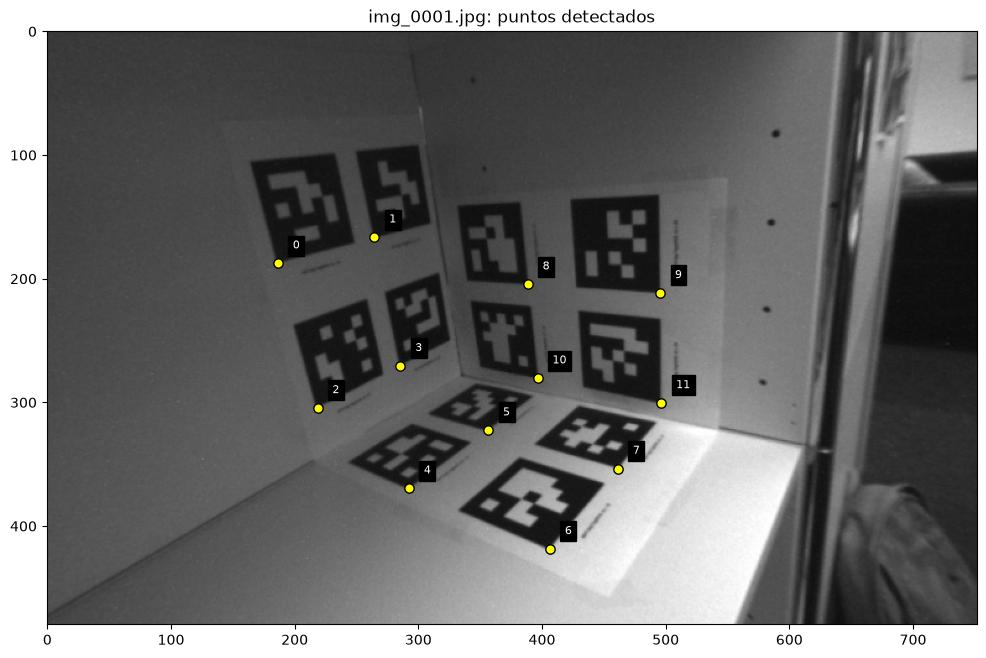

Q: (24, 12)


In [114]:
objPts_3d = pd.read_csv(os.path.join(DIR_CALIB_3D, 'p_W_corners.txt'), sep=',', header=None).to_numpy()
imgPts_3d = pd.read_csv(os.path.join(DIR_CALIB_3D, 'detected_corners.txt'), sep=r'\s+', header=None).to_numpy()
print(f'Cant. puntos 3D (U,V,W): {objPts_3d.shape[0]}')
print(f'Cant. vistas: {imgPts_3d.shape[0]}, cada una con {imgPts_3d.shape[1] // 2} puntos (u, v)')


# Usamos la primera vista (img_0001.jpg): sus 12 puntos (u, v)
imgPts_vista = imgPts_3d[0].reshape(-1, 2)
mostrar_puntos(leer_imagen(os.path.join(DIR_CALIB_3D, 'img_0001.jpg')), imgPts_vista, etiquetas=range(len(imgPts_vista)),
               titulo='img_0001.jpg: puntos detectados')

Q_3d = alc.obtenerQ3d(imgPts_vista, objPts_3d)
print('Q:', Q_3d.shape)

**b) A partir de lo resuelto en el Ejercicio 1 b), implementar la función `resolverDLT3D(Q)`, que a partir de $Q$ encuentra la matriz de proyección $M$.**

In [115]:
M = alc.resolverDLT3D(Q_3d)
print(f'M =\n{M}')
print('')
print('||Q m||_2 =', alc.norma(alc.multiplicar(Q_3d, M.reshape(-1)), 2))

M =
[[-0.0645 -0.0228  0.014  -0.8378]
 [-0.0037 -0.061  -0.0131 -0.5378]
 [-0.0001 -0.     -0.0001 -0.0051]]

||Q m||_2 = 0.008222745610321784


Notar que como buscamos M a través de resolver 

$$
\min_{\|m\|_2=1} \|Qm\|_2 ,
$$

No obtuvimos exactamente $Qm = 0$, si no que tenemos algo de error, aunque sea chico

Por lo que se vió en el 1.b, ese mínimo es el menor valor singular de $Q$: $\|Qm\|_2 = \sigma_{12}$.

**c) Una vez recuperada $M$, se la descompone en la matriz de parámetros intrínsecos $\textbf{K}$, la matriz de rotación $\textbf{R}$ y el vector de traslación $\textbf{t}$, imponiendo que $\textbf{R}$ sea ortonormal ($\textbf{RR}^T = I$). Para ello, implementar la función `devolverMatricesCalibracion3d(M)`, que devuelva $\textbf{R}$, $\textbf{t}$ y $\textbf{K}$.**

Como $M = K\,[R \mid t] = [\,KR \mid Kt\,]$, el bloque $3\times 3$ de la izquierda de $M$ es $M_{3} = KR$ y su cuarta columna es $m_4 = Kt$.

$K$ es triangular superior y $R$ es ortogonal, así que $M_3 = KR$ se parece a una factorización QR invertida. Tomamos la inversa:

$$
M_3^{-1} = (KR)^{-1} = R^{-1} K^{-1} = R^T K^{-1},
$$

donde $R^{-1} = R^T$ vale por ser $R$ ortogonal. 

Además $R^T$ es ortogonal y $K^{-1}$ es triangular superior (porque la inversa de una triangular superior también lo es). Entonces $R^T K^{-1}$ es una factorización QR de $M_3^{-1}$:

$$
M_3^{-1} = \underbrace{R^T}_{Q}\;\underbrace{K^{-1}}_{R_{QR}}
$$

La calculamos con `QR_con_GS` y despejamos $R = Q^T$ y $K = R_{QR}^{-1}$.

Para la traslación, de $m_4 = Kt$ sale $t = K^{-1} m_4$, y $K^{-1}$ ya lo tenemos del QR.

In [116]:
R_3d, t_3d, K_3d = alc.devolverMatricesCalibracion3d(M)
print(f'K =\n{K_3d}\n')
print(f'R =\n{R_3d}\n')
print(f't = {t_3d}\n')

K =
[[425.8599  -0.0156 354.4185]
 [ -0.     424.5653 256.8534]
 [ -0.      -0.       1.    ]]

R =
[[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]

t = [-18.1679 -14.5033  40.5913]



Notemos que el R obtenido es una rotación porque

En `devolverMatricesCalibracion3d` obtenemos $R$ ortonormal, ya que sale de la $Q$ de la factorización QR (lo verificamos con $RR^T = I$). Pero veamos que

$$
\det(RR^T) = \det(R)\,\det(R^T) = \det(R)\,\det(R) = \det(R)^2 .
$$

Y como $R$ es ortonormal, $RR^T = I$, entonces

$$
\det(R)^2 = \det(RR^T) = \det(I) = 1 \quad\Longrightarrow\quad \det(R) = \pm 1 .
$$

Esto nos deja dos posibilidades, $+1$ (rotación) o $-1$ (reflexión). Como la factorización QR es única salvo signos, en `devolverMatricesCalibracion3d` usamos una matriz $D$ que cumple

$$
KR = (KD)(DR),
$$

para cualquier $D = \operatorname{diag}(\pm 1, \pm 1, \pm 1)$, ya que $D^2 = I$. Y elegimos $D$ para que $\det(R) = 1$.

In [117]:
print('det(R) =', alc.determinante_3x3(R_3d))
print(f'R R^T =\n{alc.multiplicar(R_3d, alc.traspuesta(R_3d))}\n')

det(R) = 1.0
R R^T =
[[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]



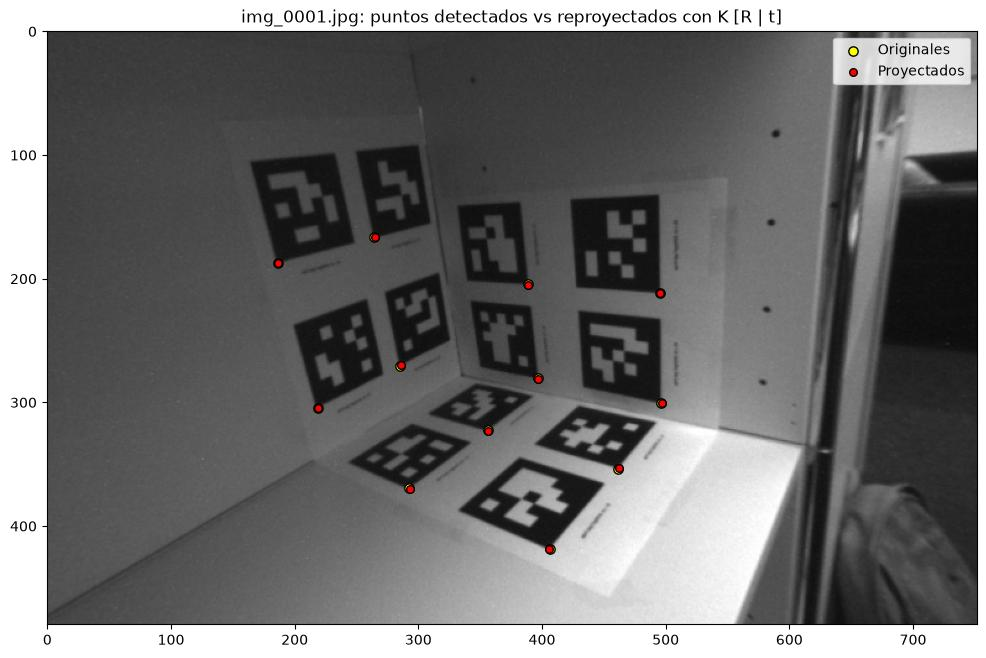

In [118]:
pts_proyectados_3d = alc.proyectarPuntosUVW(objPts_3d, K_3d, R_3d, t_3d)
mostrar_puntos(leer_imagen(os.path.join(DIR_CALIB_3D, 'img_0001.jpg')), imgPts_vista, pts_proyectados=pts_proyectados_3d,
               titulo='img_0001.jpg: puntos detectados vs reproyectados con K [R | t]')

Para medir el error de reproyección, usamos la medida RMSE mencionada en el marco teórico

$$
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} \|p_i^{\text{proy}} - p_i^{\text{obs}}\|_2^2}
$$

La idea de esta medida grandes rasgos es
- Tomar los puntos 3D conocidos y proyectarlos en la imagen con lo que estimamos: $\lambda\,(u, v, 1)^T = K\,[R \mid t]\,(U, V, W, 1)^T$.
- Compararlos con los puntos medidos en la foto. El RMSE nos devuelve en pixeles cuanto se separan en promedio.

In [119]:
print(f'RMSE de reproyección (error de reproyección): {alc.RMSE(pts_proyectados_3d, imgPts_vista):.3f} píxeles')

RMSE de reproyección (error de reproyección): 0.407 píxeles


**d) Agregar a la función `devolverMatricesCalibracion3d` un parámetro opcional que permita imponer que $α_u = α_v$ y/o $K_{12} = 0$.**

In [120]:
restricciones = [
    ('sin restricciones',           False, False),
    ('K12 = 0',                     True,  False),
    ('alpha_u = alpha_v',           False, True),
    ('K12 = 0 y alpha_u = alpha_v', True,  True),
]
for nombre, restringir_K12, restringir_K11_K22 in restricciones:
    R_r, t_r, K_r = alc.devolverMatricesCalibracion3d(M, restringir_K12, restringir_K11_K22)
    rmse_r = alc.RMSE(alc.proyectarPuntosUVW(objPts_3d, K_r, R_r, t_r), imgPts_vista)
    print(f'----- {nombre} -----')
    print(f'K =\n{K_r}')
    print(f'RMSE de reproyección: {rmse_r:.3f} píxeles\n')

----- sin restricciones -----
K =
[[425.8599  -0.0156 354.4185]
 [ -0.     424.5653 256.8534]
 [ -0.      -0.       1.    ]]
RMSE de reproyección: 0.407 píxeles

----- K12 = 0 -----
K =
[[425.8599   0.     354.4185]
 [ -0.     424.5653 256.8534]
 [ -0.      -0.       1.    ]]
RMSE de reproyección: 0.407 píxeles

----- alpha_u = alpha_v -----
K =
[[425.2126  -0.0156 354.4185]
 [ -0.     425.2126 256.8534]
 [ -0.      -0.       1.    ]]
RMSE de reproyección: 0.448 píxeles

----- K12 = 0 y alpha_u = alpha_v -----
K =
[[425.2126   0.     354.4185]
 [ -0.     425.2126 256.8534]
 [ -0.      -0.       1.    ]]
RMSE de reproyección: 0.448 píxeles



Las restricciones se imponen después de descomponer $M$: con $\gamma = K_{12} = 0$ se anula el *skew* (la inclinación entre los ejes de la imagen), y con $\alpha_u = \alpha_v$ se reemplazan las distancias focales $\alpha_u = K_{11}$ y $\alpha_v = K_{22}$ por su promedio. $R$ y $t$ no se recalculan, así que $K[R \mid t]$ ya no reconstruye exactamente $M$ y el error de reproyección puede crecer.

En nuestros datos el efecto es chico, porque la $K$ sin restricciones ya casi las cumple ($\gamma \approx -0.016$ y $\alpha_u \approx 425.9$ vs $\alpha_v \approx 424.6$):

| Restricción | RMSE (px) |
|---|---|
| ninguna | 0.407 |
| $\gamma = 0$ | 0.407 |
| $\alpha_u = \alpha_v$ | 0.448 |
| ambas | 0.448 |

<hr style="border: none; border-top: 3px solid black;">

### Ejercicio 3 - Calibración con puntos coplanares

**¿Qué rango debe tener $Q \in \mathbb{R}^{2n\times 9}$ para asegurar una solución única $H$ a menos de un factor de escala?**



Similar al Ej 1) y siguiendo el marco teórico del algoritmo DLT para el caso coplanar, queremos un $\mathbf{h} \in \mathbb{R}^9$ no nulo tal que $\mathbf{h}$ sea solución única a menos de un factor de escala de $Q\mathbf{h} = 0$. Eso pasa si y solo si el núcleo de $Q$ tiene dimensión 1:

$$
\dim(\operatorname{Nu}(Q)) = 1.
$$

Por el teorema de la dimensión, con $Q : \mathbb{R}^9 \to \mathbb{R}^{2n}$:

$$
9 = \dim(\operatorname{Nu}(Q)) + \operatorname{rg}(Q) = 1 + \operatorname{rg}(Q) \Longrightarrow \operatorname{rg}(Q) = 8.
$$

Como cada punto aporta 2 filas, $\operatorname{rg}(Q) \le \min(2n, 9)$. Para tener rango 8 hace falta

$$
8 \le 2n \Longrightarrow n \ge 4,
$$

es decir, al menos 4 puntos, y además que no hayan 3 puntos alineados ya que si no, las ecuaciones de esos puntos dejan de ser L.I., el rango termina siendo < 8 y la homografía $\mathbf{h}$ deja de ser única (salvo escala).

En nuestro caso usamos las 4 esquinas extremas del tablero, para asegurarnos de no tener 3 puntos alineados, así que $Q \in \mathbb{R}^{8\times 9}$ tiene rango 8.

**Implementar la función obtenerQ2d(imgPts, objPts) que devuelve la matriz Q a partir
de la ecuación 11**

En cada vista marcamos a ojo las 4 esquinas internas extremas del tablero. En las coordenadas del tablero son $(0, 0)$, $(300, 0)$, $(0, 180)$ y $(300, 180)$ mm, porque las esquinas internas están en $(30i,\ 30j)$ con $i = 0..10$, $j = 0..6$.

Para ubicarlas, mostramos cada imagen, leemos aproximadamente las coordenadas $(u, v)$ de cada esquina guiándonos con los ejes de la figura y dibujamos los puntos encima para corregirlos hasta que caigan sobre las esquinas. Siempre las ordenamos igual: superior izquierda, superior derecha, inferior izquierda e inferior derecha, para que se correspondan con los puntos del tablero. Por ejemplo, para $\texttt{Im\_R\_1}$:

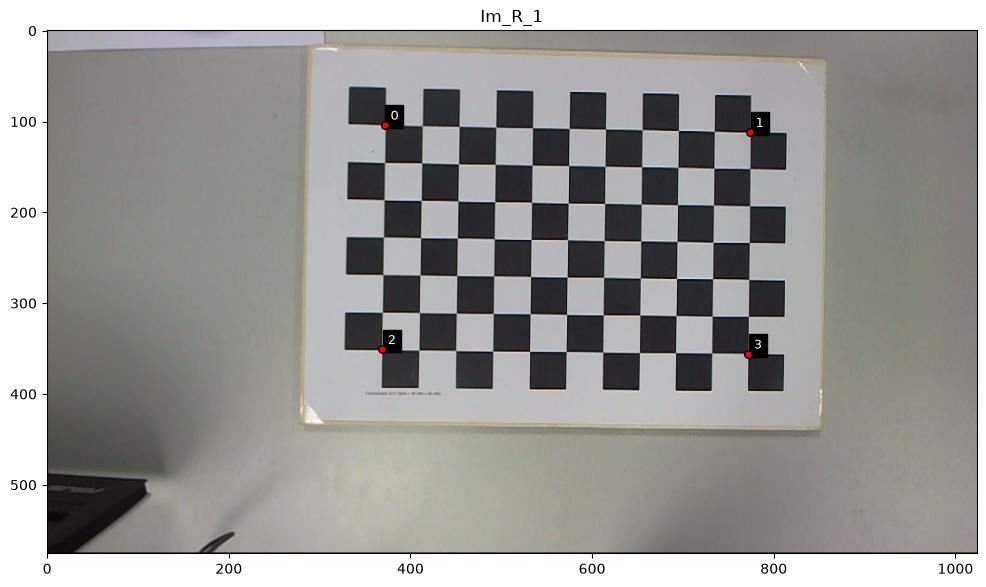

In [121]:
# Ejemplo con Im_R_1: las 4 esquinas internas extremas
img_ejemplo = leer_imagen(os.path.join(DIR_CALIB_COPLANAR, 'Im_R_1.png'))
esquinas_ejemplo = np.array([
    [372, 104],   # 0: superior izquierda -> (0, 0) mm
    [774, 112],   # 1: superior derecha   -> (300, 0) mm
    [369, 351],   # 2: inferior izquierda -> (0, 180) mm
    [772, 356],   # 3: inferior derecha   -> (300, 180) mm
])

plt.figure(figsize=(12, 8))
plt.imshow(img_ejemplo)
plt.scatter(esquinas_ejemplo[:, 0], esquinas_ejemplo[:, 1], s=30, c='red', edgecolors='black', zorder=4)
for i in range(esquinas_ejemplo.shape[0]):
    plt.text(esquinas_ejemplo[i, 0] + 6, esquinas_ejemplo[i, 1] - 6, str(i),
             color='white', backgroundcolor='black', fontsize=9)
plt.title('Im_R_1')
plt.show()

Repetimos lo mismo para las 20 vistas y dejamos los puntos obtenidos en el código:

In [122]:
# Esquinas internas extremas del tablero en mm (U, V), con W = 0. Son las mismas para todas las vistas
objPts_tablero = np.array([
    [0, 0],       # superior izquierda
    [300, 0],     # superior derecha
    [0, 180],     # inferior izquierda
    [300, 180],   # inferior derecha
])

# Las mismas esquinas en píxeles, en cada vista Im_R_k.
# Una fila por vista: [u0, v0, u1, v1, u2, v2, u3, v3], en el mismo orden que objPts_tablero
imgPts_vistas = np.array([
    [372, 104, 774, 112, 369, 351, 772, 356],   # Im_R_1
    [384, 175, 778,  84, 441, 415, 832, 323],   # Im_R_2
    [384, 135, 793, 115, 399, 389, 807, 363],   # Im_R_3
    [405, 114, 817, 109, 410, 367, 816, 357],   # Im_R_4
    [415,  75, 819, 110, 397, 328, 804, 356],   # Im_R_5
    [408,  92, 813, 108, 403, 346, 809, 354],   # Im_R_6
    [405, 146, 818, 132, 416, 398, 820, 380],   # Im_R_7
    [390, 133, 796, 114, 409, 397, 817, 359],   # Im_R_8
    [360, 150, 778,  72, 412, 402, 812, 322],   # Im_R_9
    [387,  82, 795,  61, 397, 333, 827, 305],   # Im_R_10
    [381,  64, 805,  83, 375, 322, 783, 337],   # Im_R_11
    [350, 147, 767, 141, 359, 410, 771, 390],   # Im_R_12
    [421, 145, 826, 189, 399, 407, 807, 433],   # Im_R_13
    [387, 137, 800, 162, 381, 417, 797, 411],   # Im_R_14
    [427, 178, 877, 160, 442, 435, 865, 424],   # Im_R_15
    [462, 148, 866, 174, 456, 425, 861, 421],   # Im_R_16
    [369, 105, 782, 103, 374, 358, 780, 352],   # Im_R_17
    [374, 136, 827,  94, 409, 396, 820, 353],   # Im_R_18
    [399, 130, 841,  95, 426, 389, 836, 353],   # Im_R_19
    [393,  72, 820,  73, 404, 348, 817, 328],   # Im_R_20
])
print('Vistas:', imgPts_vistas.shape[0], '  Esquinas por vista:', imgPts_vistas.shape[1] // 2)

Vistas: 20   Esquinas por vista: 4


**Homografía de cada vista.** Como el tablero es plano ($W = 0$), cada vista queda descripta por una homografía $\mathbf{H}$ de 3×3 con 8 grados de libertad. Cada punto aporta 2 ecuaciones, así que alcanzan 4 puntos sin 3 alineados para que $Q \in \mathbb{R}^{8\times 9}$ tenga rango 8. La calculamos con $\texttt{resolverDLT2D}$ .

In [123]:
Hs = []
for k in range(imgPts_vistas.shape[0]):
    imgPts_k = imgPts_vistas[k].reshape(-1, 2)
    Hs.append(alc.resolverDLT2D(imgPts_k, objPts_tablero))
print(len(Hs), 'homografías')

20 homografías


**Validación**

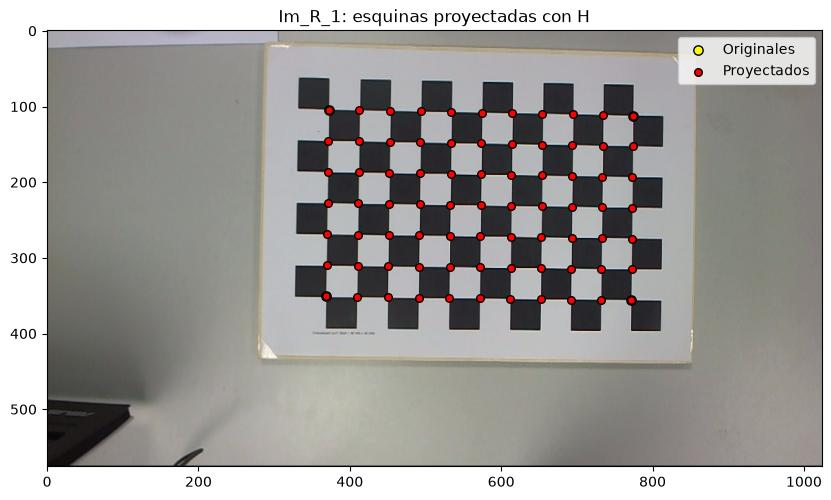

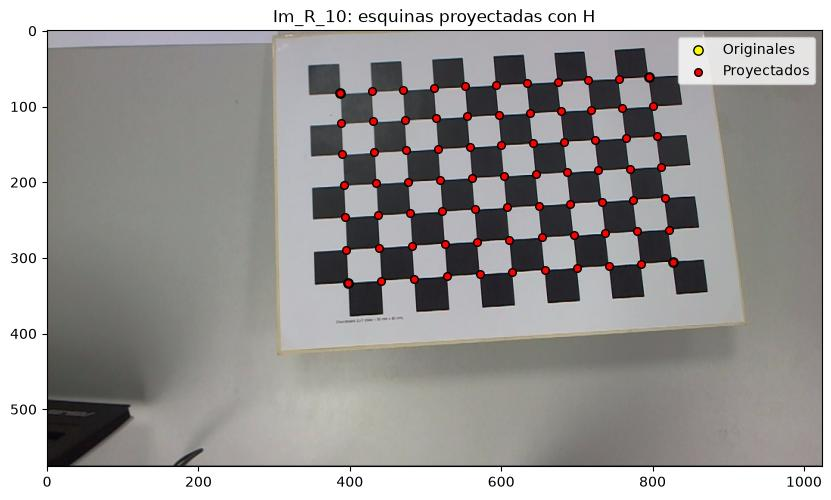

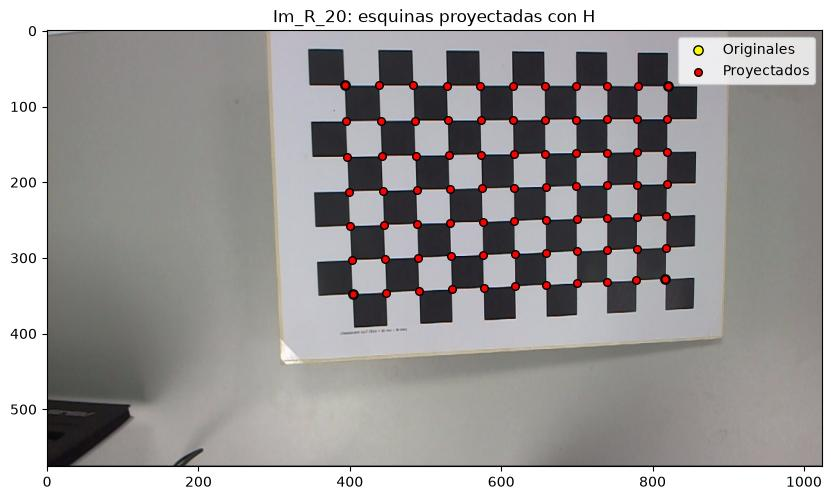

In [124]:
# Las 11 x 7 esquinas internas del tablero (mm)
esquinas = []
for j in range(7):
    for i in range(11):
        esquinas.append([30.0 * i, 30.0 * j])
esquinas = np.array(esquinas)

# Esquinas detectadas
for k in [0, 9, 19]:
    proyectadas = alc.aplicarHomografia(Hs[k], esquinas)
    img_k = leer_imagen(os.path.join(DIR_CALIB_COPLANAR, f'Im_R_{k + 1}.png'))
    mostrar_puntos(img_k, imgPts_vistas[k].reshape(-1, 2), pts_proyectados=proyectadas,
                   titulo=f'Im_R_{k + 1}: esquinas proyectadas con H', figsize=(10, 6))

**Implementar la función `armarA(Hlst)` que recibe una lista de matrices $Hj$ correspondientes a las $N$ capturas de las miras, obtenidas a partir de la resolución del sistema planteado en la ecuación 11**

In [125]:
A = alc.armarA(Hs)
print(f"A: 2nx6, con n la cantidad de vistas -> A: {A.shape[0]}x{A.shape[1]}")
print('A=')
print(A)

A: 2nx6, con n la cantidad de vistas -> A: 40x6
A=
[[-0.0097  0.6158  0.014  -0.      0.     -0.    ]
 [ 0.6178  0.0476 -0.6137  0.      0.      0.    ]
 [ 0.1451  0.5545 -0.133   0.      0.      0.    ]
 [ 0.5432 -0.5566 -0.5655  0.     -0.     -0.    ]
 [ 0.04    0.6495 -0.0261  0.      0.      0.    ]
 [ 0.6548 -0.1321 -0.6441  0.0001 -0.      0.    ]
 [ 0.0281  0.6562 -0.0042  0.      0.      0.    ]
 [ 0.6524 -0.0649 -0.6591  0.0001 -0.0001 -0.    ]
 [-0.0525  0.6382  0.0574 -0.      0.     -0.    ]
 [ 0.6536  0.2201 -0.6232  0.0001  0.      0.    ]
 [-0.015   0.6483  0.0294 -0.      0.     -0.    ]
 [ 0.6631  0.0894 -0.6335  0.0001  0.      0.    ]
 [ 0.051   0.6562 -0.0179  0.0001  0.      0.    ]
 [ 0.6427 -0.139  -0.6682  0.     -0.0001 -0.    ]
 [ 0.041   0.6922 -0.0153 -0.      0.0001 -0.    ]
 [ 0.7427 -0.1091 -0.6445  0.0002  0.      0.    ]
 [ 0.1747  0.6437 -0.1185  0.0001  0.      0.    ]
 [ 0.6067 -0.5902 -0.6758  0.     -0.0002 -0.    ]
 [-0.0299  0.6368 -0.0293 -0.00

**Implementar `calcularMatrizK2D(A)` que recibe la matriz $A$ y calcula la matriz $K$.**

Cada $H \sim K\,[r_1\ r_2\ t]$. Si llamamos $c_1, c_2, c_3$ a las columnas de $H$, salvo un factor de escala $s$ vale:

$$
c_1 = sKr_1, \qquad c_2 = sKr_2, \qquad c_3 = sKt
$$

Despejando $r_1$ y $r_2$:

$$
r_1 = \tfrac1s K^{-1}c_1, \qquad r_2 = \tfrac1s K^{-1}c_2
$$

Como $r_1$ y $r_2$ son ortonormales, si llamamos $B = K^{-T}K^{-1}$:

$$
\begin{aligned}
r_1^T r_2 = 0 \;&\Longrightarrow\; \tfrac{1}{s^2}\, c_1^T K^{-T}K^{-1} c_2 = 0 \;\Longrightarrow\; c_1^T B\, c_2 = 0, \\
r_1^T r_1 = r_2^T r_2 \;&\Longrightarrow\; \tfrac{1}{s^2}\, c_1^T K^{-T}K^{-1} c_1 = \tfrac{1}{s^2}\, c_2^T K^{-T}K^{-1} c_2 \;\Longrightarrow\; c_1^T B\, c_1 = c_2^T B\, c_2 .
\end{aligned}
$$

$B$ es simétrica, así que tiene 6 incógnitas. Para escribir cada ecuación como una fila de $A$, desarrollamos $c_i^T B\, c_j$, con $c_i = (c_{i1}, c_{i2}, c_{i3})$:

$$
\begin{aligned}
c_i^T B\, c_j = \;& B_{11}\, c_{i1}c_{j1} + B_{12}\, c_{i1}c_{j2} + B_{13}\, c_{i1}c_{j3} \\
+\;& B_{21}\, c_{i2}c_{j1} + B_{22}\, c_{i2}c_{j2} + B_{23}\, c_{i2}c_{j3} \\
+\;& B_{31}\, c_{i3}c_{j1} + B_{32}\, c_{i3}c_{j2} + B_{33}\, c_{i3}c_{j3}
\end{aligned}
$$

Como $B$ es simétrica ($B_{ij} = B_{ji}$), agrupamos los términos:

$$
\begin{aligned}
c_i^T B\, c_j = \;& B_{11}\, c_{i1}c_{j1} \\
+\;& B_{12}\,(c_{i1}c_{j2} + c_{i2}c_{j1}) \\
+\;& B_{22}\, c_{i2}c_{j2} \\
+\;& B_{13}\,(c_{i3}c_{j1} + c_{i1}c_{j3}) \\
+\;& B_{23}\,(c_{i3}c_{j2} + c_{i2}c_{j3}) \\
+\;& B_{33}\, c_{i3}c_{j3} \\
=\;& v_{ij}^T\, b
\end{aligned}
$$

donde

$$
b = \begin{pmatrix} B_{11} \\ B_{12} \\ B_{22} \\ B_{13} \\ B_{23} \\ B_{33} \end{pmatrix}, \qquad
v_{ij} = \begin{pmatrix} c_{i1}c_{j1} \\ c_{i1}c_{j2} + c_{i2}c_{j1} \\ c_{i2}c_{j2} \\ c_{i3}c_{j1} + c_{i1}c_{j3} \\ c_{i3}c_{j2} + c_{i2}c_{j3} \\ c_{i3}c_{j3} \end{pmatrix}.
$$

Entonces cada vista da 2 ecuaciones lineales en $b$:

$$
v_{12}^T\, b = 0, \qquad (v_{11} - v_{22})^T\, b = 0 .
$$

Con las 20 vistas armamos $A \in \mathbb{R}^{40\times 6}$ ($\texttt{armarA}$) y resolvemos $\min_{\|b\|=1} \|Ab\|$.

Como $b$ sale a menos de un signo, si $B$ no es definida positiva la multiplicamos por $-1$. Después, con Cholesky $B = LL^T$, obtenemos $K = (L^T)^{-1}$.

Por último, como $B$ se conoce salvo escala, normalizamos $K$ para que $K_{33} = 1$.

In [126]:
K = alc.calcularMatrizK2D(A)
print(K)

[[760.8588  -1.0675 522.9704]
 [  0.     773.2662 302.6043]
 [  0.       0.       1.    ]]


El punto principal (centro óptico) $(u_0, v_0) \approx (523,\ 303)$ queda cerca del centro de la imagen ($1024 \times 576$ px, centro en $(512,\ 288)$), y las distancias focales $\alpha_u \approx 761$ y $\alpha_v \approx 773$ son parecidas. El *skew* $\gamma \approx -1.07$ es chico comparado con las focales.

**Implementar `obtenerPose2D(Hj, K)` que devuelve la pose de la vista $j$ como $Rj$ y $tj$ a partir de la matriz $K$ y la $Hj$ correspondiente.**

Pose de $\texttt{Im\_R\_1}$, $\texttt{Im\_R\_10}$ y $\texttt{Im\_R\_20}$.

De $\mathbf{H} = \lambda\mathbf{K}[\mathbf{r}_1\ \mathbf{r}_2\ \mathbf{t}]$:

$$\lambda = \frac{1}{\|\mathbf{K}^{-1}\mathbf{c}_1\|} =  \frac{1}{s}, \quad \mathbf{r}_1 = \lambda \mathbf{K}^{-1}\mathbf{c}_1, \quad \mathbf{r}_2 = \lambda \mathbf{K}^{-1}\mathbf{c}_2, \quad \mathbf{r}_3 = \mathbf{r}_1 \times \mathbf{r}_2, \quad \mathbf{t} = \lambda \mathbf{K}^{-1}\mathbf{c}_3$$

Como $\mathbf{h}$ sale de $\min_{\|\mathbf{h}\|=1}\|Q\mathbf{h}\|$, puede salir $\mathbf{H}$ o $-\mathbf{H}$: si queda $t_z < 0$ (el tablero detrás de la cámara), cambiamos el signo de $\mathbf{r}_1$, $\mathbf{r}_2$ y $\mathbf{t}$ ($\mathbf{r}_3$ no cambia ya que $\mathbf{r}_3$ = $\mathbf{r}_1 \times \mathbf{r}_2$).

Finalmente,  ortonormalizamos $\mathbf{R}$ con Gram-Schmidt para que sea efectivamente una matriz de rotación. 

In [127]:
for k in [0, 9, 19]:
    R, t = alc.obtenerPose2D(Hs[k], K)
    print(f'Im_R_{k + 1}')
    print('R =')
    print(R)
    print('t =', t)
    print()

Im_R_1
R =
[[ 0.9996 -0.0135 -0.0233]
 [ 0.0137  0.9999  0.0074]
 [ 0.0232 -0.0077  0.9997]]
t = [-111.9629 -144.6632  563.2464]

Im_R_10
R =
[[ 0.9972  0.0686 -0.0307]
 [-0.0627  0.9845  0.1637]
 [ 0.0414 -0.1613  0.986 ]]
t = [ -98.4426 -156.8036  549.6306]

Im_R_20
R =
[[ 0.9891  0.0264 -0.1447]
 [-0.0399  0.9951 -0.0909]
 [ 0.1416  0.0957  0.9853]]
t = [ -85.4893 -148.8837  499.2393]



<hr style="border: none; border-top: 3px solid black;">

### Ejercicio 4 - Fútbol

**Para la foto $\texttt{gol-enzo.png}$, estimar la homografía $\mathbf{H}$ del plano de la cancha a la imagen y utilizarla para:**

**a) Calcular la distancia en línea recta, medida sobre el piso, a la que se encuentra Enzo de la línea del arco cuando patea al gol. Para ello, llevar la posición de sus pies de la imagen a la cancha mediante $\mathbf{H}^{-1}$.**

**Sistema de coordenadas.** Tomamos el sistema del plano $\texttt{estadio\_azteca.png}$: origen en la esquina inferior izquierda, $U$ a lo largo de la cancha ($0$ a $105$ m) y $V$ a lo ancho ($0$ a $68$ m). En la foto, Enzo patea hacia el arco de $U = 0$. Como la cámara mira hacia ese arco desde adentro de la cancha, lo que en la foto está a la izquierda tiene $V$ menor.

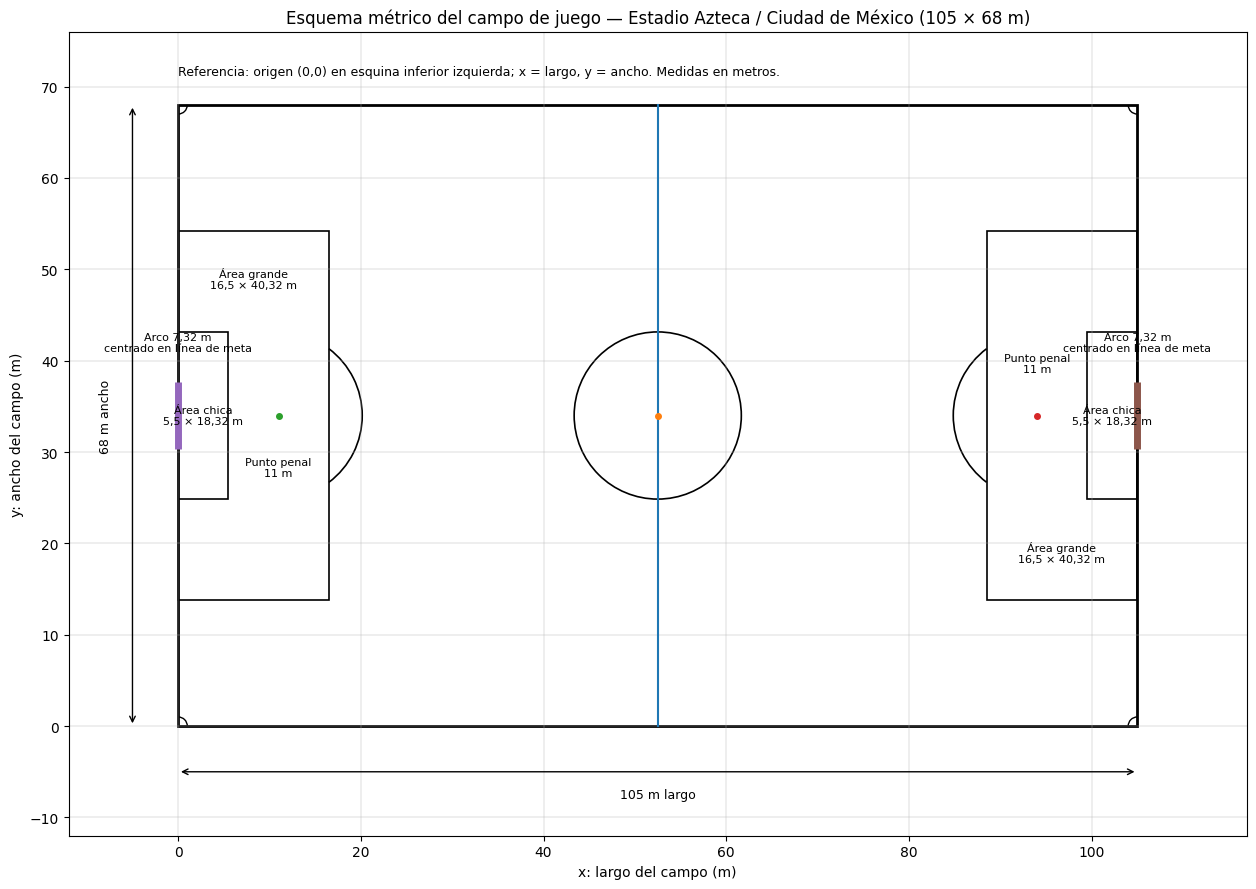

**Puntos de referencia.** Para estimar $\mathbf{H}$ necesitamos puntos del **piso** cuya posición conozcamos tanto en la cancha (metros) como en la foto (píxeles). Elegimos 5 puntos marcados en el piso (las esquinas frontales del área chica, el punto penal y la base de los palos), porque es más fácil estimar su posición en la cancha. Como mínimo necesitamos 4 (sin 3 alineados) para obtener $\mathbf{H}$, así que tenemos más que suficientes; usar más ayuda a compensar los errores de marcarlos a mano.

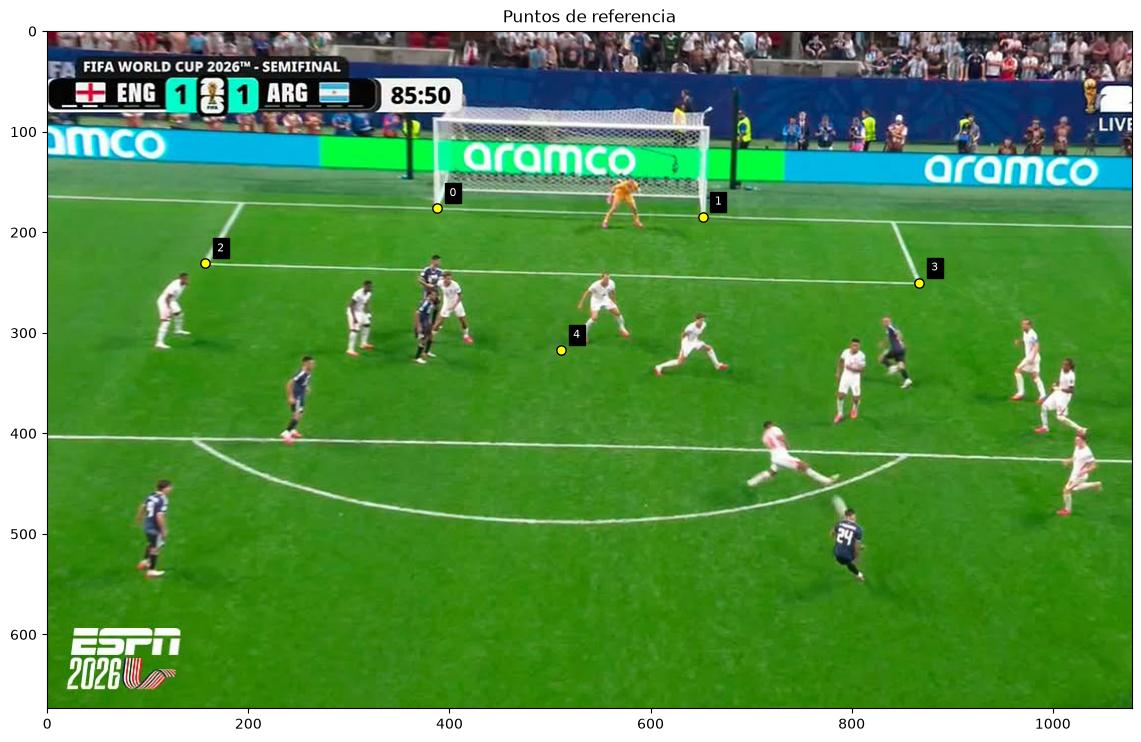

In [128]:
img_gol = leer_imagen(os.path.join(DIR_FUTBOL, 'test-gol-enzo.png'))

# Puntos de referencia en la cancha, (U, V) en metros
objPts_gol = np.array([
    [0.0,  30.34],   # 0: base del palo izquierdo
    [0.0,  37.66],   # 1: base del palo derecho
    [5.5,  24.84],   # 2: área chica, esquina frontal izquierda
    [5.5,  43.16],   # 3: área chica, esquina frontal derecha
    [11.0, 34.0],    # 4: punto penal
])

# Los mismos puntos en la foto, (u, v) en píxeles, marcados a mano
imgPts_gol = np.array([
    [388.0, 176.0],  # 0: base del palo izquierdo
    [652.0, 184.5],  # 1: base del palo derecho
    [157.0, 231.0],  # 2: área chica, esquina frontal izquierda
    [867.0, 250.0],  # 3: área chica, esquina frontal derecha
    [511.0, 317.0],  # 4: punto penal
])

mostrar_puntos(img_gol, imgPts_gol, etiquetas=range(imgPts_gol.shape[0]), titulo='Puntos de referencia', figsize=(14, 9))

Las coordenadas en metros salen del plano: el arco mide $7.32$ m (palos en $V = 34 \pm 3.66$), el área chica $5.5 \times 18.32$ m ($V = 34 \pm 9.16$) y el penal está a $11$ m. Las coordenadas en píxeles se marcaron a mano sobre la imagen, tomando el centro de las líneas blancas y la base de los palos.


**Estimación de $\mathbf{H}$.** Con las correspondencias resolvemos $Q\mathbf{h} = 0$ con $\texttt{resolverDLT2D}$. La $\mathbf{H}$ obtenida lleva puntos de la cancha a la imagen, y su inversa $\mathbf{H}^{-1}$ lleva puntos de la imagen a la cancha.

In [129]:
H_gol = alc.resolverDLT2D(imgPts_gol, objPts_gol)
H_gol_inv = alc.inversa(H_gol)
print("H=")
print(H_gol)

print("H^-1=")
print(H_gol_inv)

H=
[[  -4.9321   23.0604 -455.2715]
 [   5.0931    0.8026   86.1349]
 [  -0.0086    0.0008    0.6053]]
H^-1=
[[ -0.0044   0.1504 -24.7237]
 [  0.0402   0.0724  19.9106]
 [ -0.0001   0.002    1.2764]]


**Pie de Enzo.** Marcamos a ojo en la foto el pie de apoyo de Enzo al patear y elegimos un punto de la línea del arco para luego trazar la recta:

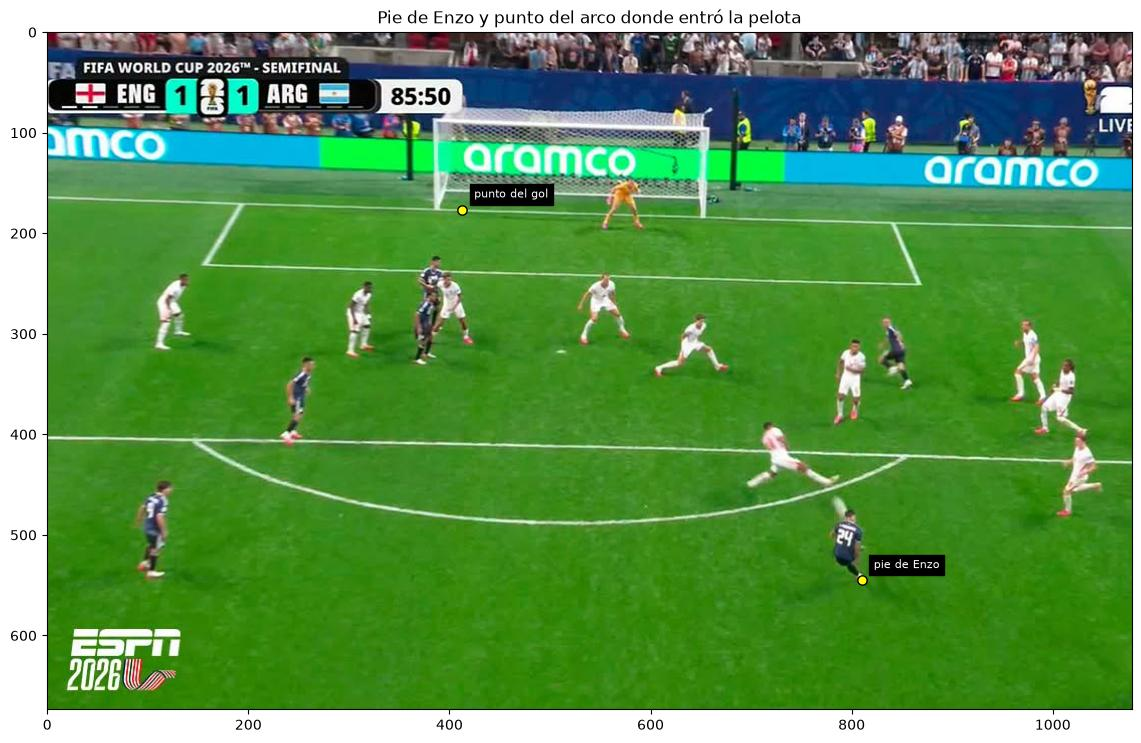

In [130]:
# Pie de apoyo de Enzo al patear (px), marcado a ojo
pie_enzo_img = np.array([[810.0, 545.0]])
# Punto de la línea del arco donde entró la pelota (m), entre los palos (V = 30.34 a 37.66)
punto_gol = np.array([0.0, 31.0])
# Lo llevamos a la foto con H para poder dibujarlo
punto_gol_img = alc.aplicarHomografia(H_gol, np.array([punto_gol]))

mostrar_puntos(img_gol, np.vstack((pie_enzo_img, punto_gol_img)), etiquetas=['pie de Enzo', 'punto del gol'],
               titulo='Pie de Enzo y punto del arco donde entró la pelota', figsize=(14, 9))

**Posición y distancia.** Llevamos el pie de Enzo $(u, v)$ a la cancha con $\mathbf{H}^{-1}$ y medimos la distancia en línea recta sobre el piso hasta el punto del gol $(U_{gol}, V_{gol}) = (0,\ 31)$:

$$\begin{bmatrix} q_1 \\ q_2 \\ q_3 \end{bmatrix} = \mathbf{H}^{-1} \begin{bmatrix} u \\ v \\ 1 \end{bmatrix}, \quad U_{enzo} = \frac{q_1}{q_3},\quad V_{enzo} = \frac{q_2}{q_3},$$
$$ \qquad d = \sqrt{(U_{enzo} - U_{gol})^2 + (V_{enzo} - V_{gol})^2} = \sqrt{U_{enzo}^2 + (V_{enzo} - 31)^2}.$$

Enzo en la cancha: U = 23.39 m, V = 40.04 m
Distancia al arco (punto donde entró la pelota): 25.07 m


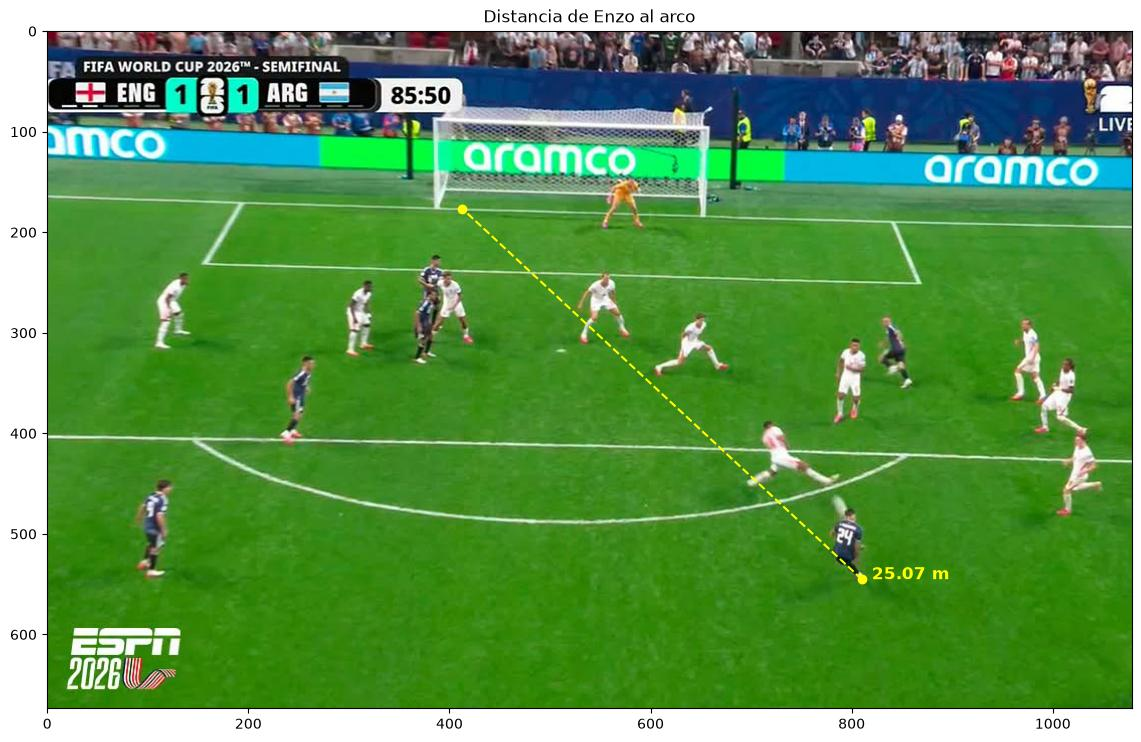

In [131]:
U_enzo, V_enzo = alc.aplicarHomografia(H_gol_inv, pie_enzo_img)[0]
distancia = np.sqrt((U_enzo - punto_gol[0])**2 + (V_enzo - punto_gol[1])**2)
print(f'Enzo en la cancha: U = {U_enzo:.2f} m, V = {V_enzo:.2f} m')
print(f'Distancia al arco (punto donde entró la pelota): {distancia:.2f} m')

plt.figure(figsize=(14, 9))
plt.imshow(img_gol)
plt.plot([pie_enzo_img[0, 0], punto_gol_img[0, 0]], [pie_enzo_img[0, 1], punto_gol_img[0, 1]], '--o', color='yellow', linewidth=1.5, markersize=6)
plt.text(pie_enzo_img[0, 0] + 10, pie_enzo_img[0, 1], f'{distancia:.2f} m', color='yellow', fontsize=12, weight='bold')
plt.title('Distancia de Enzo al arco')
plt.show()

**b) Ubicar espacialmente todos los jugadores argentinos y dibujar un círculo de 1 metro de radio sobre el piso, como se muestra en la fig. 4. Para ello, definir el círculo en coordenadas de la cancha y proyectar sus puntos a la imagen mediante $\mathbf{H}$.**

Usamos la misma $\mathbf{H}$ del 4.a. Para cada jugador: llevamos su pie a la cancha con $\mathbf{H}^{-1}$, armamos ahí el círculo de 1 m de radio con $\texttt{circuloEnCancha}$, que lo parametriza como $(U, V) = (U_0 + r\cos\theta,\ V_0 + r\sin\theta)$ con $\theta \in [0, 2\pi]$, y proyectamos sus puntos a la foto con $\mathbf{H}$.

Los pies se marcaron a mano. El jugador de atrás del grupo del medio tiene los pies tapados por su compañero, así que su posición se estimó por la bota que se ve y es la menos precisa.

In [132]:
def circuloEnCancha(centro, radio, n):
    """
    centro el centro (U0, V0) de la circunferencia, en metros
    radio el radio de la circunferencia, en metros
    n la cantidad de divisiones de la circunferencia
    Retorna la matriz de (n+1) x 2 con los puntos (U, V) = (U0 + r cos(theta), V0 + r sin(theta)) de la circunferencia
    sobre el piso, recorridos en orden y repitiendo el primero al final para cerrar la curva con plt.plot.
    """
    U0, V0 = centro
    # Ángulos equiespaciados entre 0 y 2*pi (incluido, para cerrar la curva)
    theta = 2 * np.pi * np.arange(n + 1) / n
    return np.vstack([U0 + radio * np.cos(theta), V0 + radio * np.sin(theta)]).T

Jugador 0: U = 23.69 m, V = 26.77 m
Jugador 1: U = 16.88 m, V = 28.46 m
Jugador 2: U = 9.93 m, V = 31.02 m
Jugador 3: U = 12.07 m, V = 30.87 m
Jugador 4: U = 12.90 m, V = 42.00 m
Jugador 5: U = 23.39 m, V = 40.04 m


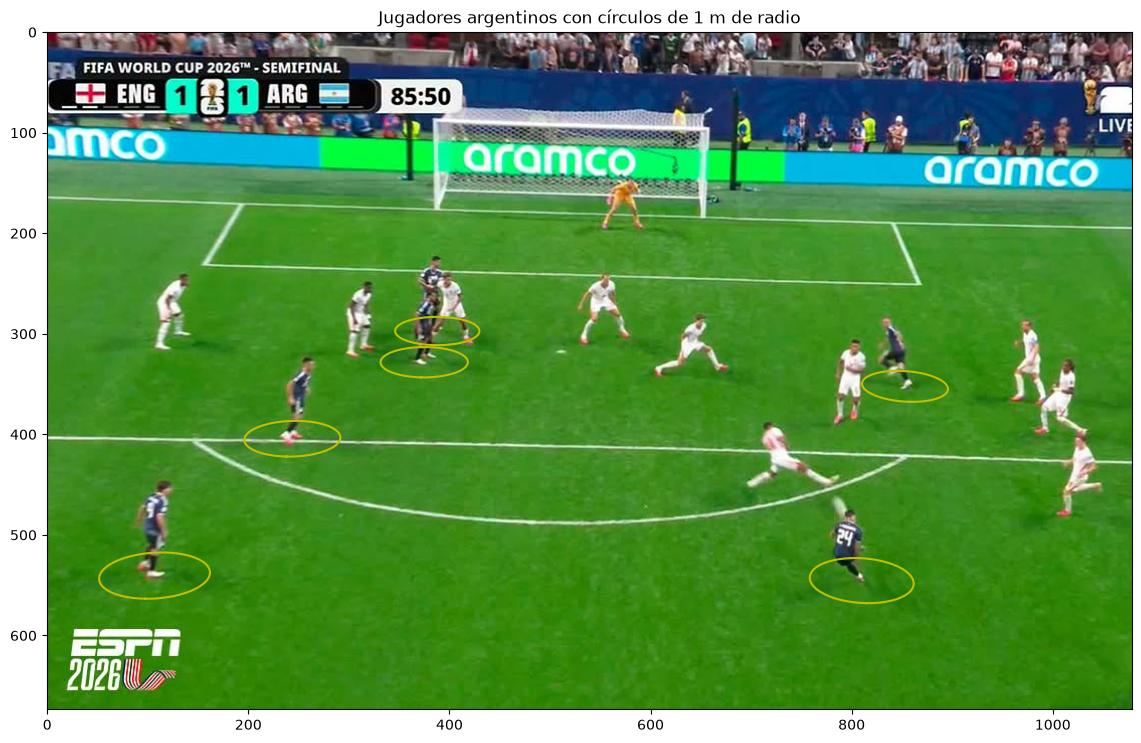

In [133]:
# Pies de los jugadores argentinos (px)
pies_argentinos_img = np.array([
    [107.0, 540.0],   # abajo a la izquierda
    [244.0, 404.0],   # sobre la línea del área
    [388.0, 297.0],   # el de atrás del grupo del medio
    [375.0, 328.0],   # el de adelante del grupo del medio
    [853.0, 352.0],   # a la derecha
    [810.0, 545.0],   # Enzo
])

pies_cancha = alc.aplicarHomografia(H_gol_inv, pies_argentinos_img)
for i in range(pies_cancha.shape[0]):
    print(f'Jugador {i}: U = {pies_cancha[i, 0]:.2f} m, V = {pies_cancha[i, 1]:.2f} m')

plt.figure(figsize=(14, 9))
plt.imshow(img_gol)
for i in range(pies_cancha.shape[0]):
    circulo_img = alc.aplicarHomografia(H_gol, circuloEnCancha(pies_cancha[i], 1.0, 50))
    plt.plot(circulo_img[:, 0], circulo_img[:, 1], 'y-', linewidth=1.5)
plt.title('Jugadores argentinos con círculos de 1 m de radio')
plt.show()

**Para la foto $\texttt{posibleoffside.jpg}$, estimar su propia homografía $\mathbf{H}$ y utilizarla para:**

**c) Trazar una recta paralela a la línea de fondo de la cancha que toque el pie del último defensor (es decir, el penúltimo jugador adversario, contando al arquero) para determinar si los jugadores de blanco estaban en fuera de juego. La recta se define en coordenadas de la cancha y se proyecta a la imagen mediante $\mathbf{H}$.**

![posible offside](futbol/test-fuera-de-juego.png)

**Sistema de coordenadas.** Es otra foto (otra cámara/pose), así que estimamos una homografía nueva $\mathbf{H}$ con puntos de esta imagen. Usamos el mismo sistema de coordenadas del plano del 4.a: los de blanco atacan el arco de $U = 105$ (a la derecha de la foto) y la banda de arriba de la foto es $V = 68$.

**Puntos de referencia.** Elegimos 6 puntos marcados en el piso y calculando sus posiciones usando las medidas de $\texttt{estadio\_azteca.png}$

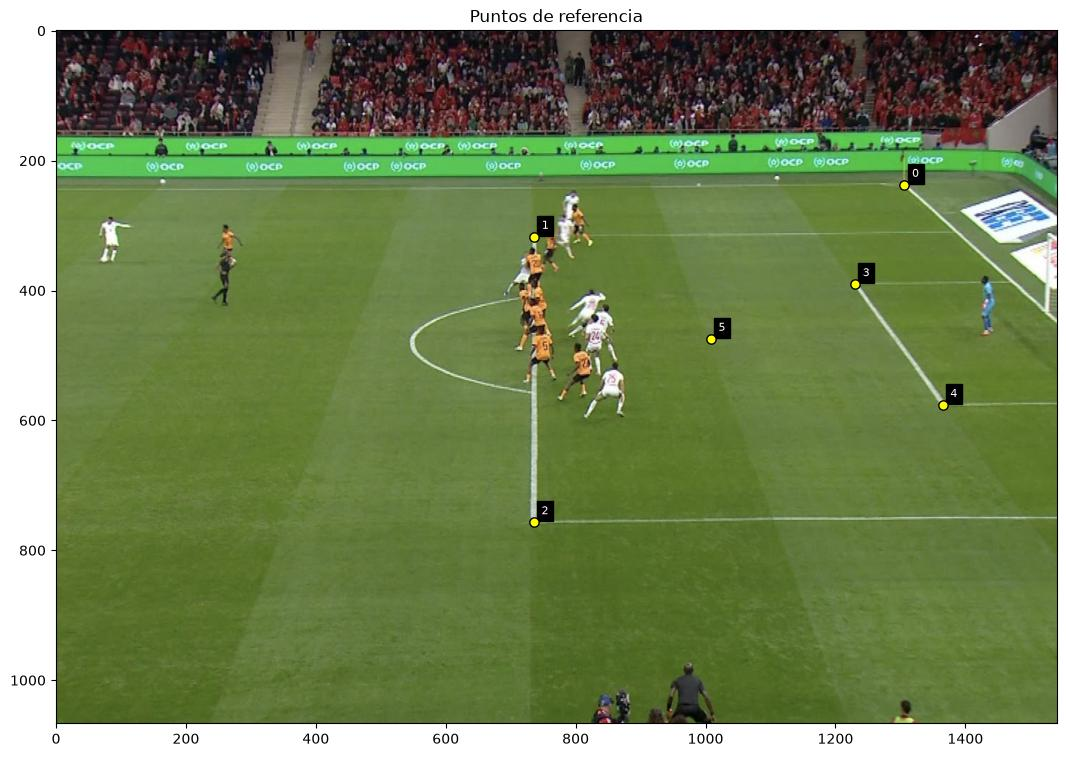

In [134]:
img_offside = leer_imagen(os.path.join(DIR_FUTBOL, 'test-fuera-de-juego.png'))

# Puntos de referencia en la cancha, (U, V) en metros
objPts_offside = np.array([
    [105.0, 68.0],    # 0: córner (banderín)
    [88.5,  54.16],   # 1: área grande, esquina de arriba sobre la línea del área
    [88.5,  13.84],   # 2: área grande, esquina de abajo sobre la línea del área
    [99.5,  43.16],   # 3: área chica, esquina frontal de arriba
    [99.5,  24.84],   # 4: área chica, esquina frontal de abajo
    [94.0,  34.0],    # 5: punto penal
])

# Los mismos puntos en la foto, (u, v) en píxeles, marcados a mano
imgPts_offside = np.array([
    [1306.0, 237.0],  # 0: córner (banderín)
    [736.0,  317.0],  # 1: área grande, esquina de arriba sobre la línea del área
    [735.5,  756.5],  # 2: área grande, esquina de abajo sobre la línea del área
    [1230.0, 390.0],  # 3: área chica, esquina frontal de arriba
    [1365.0, 576.0],  # 4: área chica, esquina frontal de abajo
    [1008.0, 474.0],  # 5: punto penal
])

mostrar_puntos(img_offside, imgPts_offside, etiquetas=range(imgPts_offside.shape[0]), titulo='Puntos de referencia', figsize=(14, 9))

Las coordenadas en metros salen del plano: el área grande mide $16.5 \times 40.32$ m (línea del área en $U = 105 - 16.5 = 88.5$, esquinas en $V = 34 \pm 20.16$), el área chica $5.5 \times 18.32$ m ($U = 99.5$, $V = 34 \pm 9.16$) y el penal está a $11$ m ($U = 94$). Las coordenadas en píxeles se marcaron a mano sobre la imagen, tomando el centro de las líneas blancas.

**Estimación de $\mathbf{H}$.** Igual que en el 4.a, resolvemos $Q\mathbf{h} = 0$ con $\texttt{resolverDLT2D}$ y calculamos $\mathbf{H}^{-1}$ para llevar puntos de la imagen a la cancha.

In [135]:
H_off = alc.resolverDLT2D(imgPts_offside, objPts_offside)
H_off_inv = alc.inversa(H_off)
print("H=")
print(H_off)

print("H^-1=")
print(H_off_inv)

H=
[[   15.5888     3.0831 -1255.7293]
 [   -0.1638    -1.1403   201.693 ]
 [   -0.         0.0042     0.1735]]
H^-1=
[[  0.0683   0.3795  53.2085]
 [ -0.0012  -0.1737 193.0043]
 [  0.       0.0043   1.1344]]


**Validación.** Proyectamos la línea de fondo, la banda de arriba y el lado de arriba del área grande, que no se usaron enteras para estimar $\mathbf{H}$.

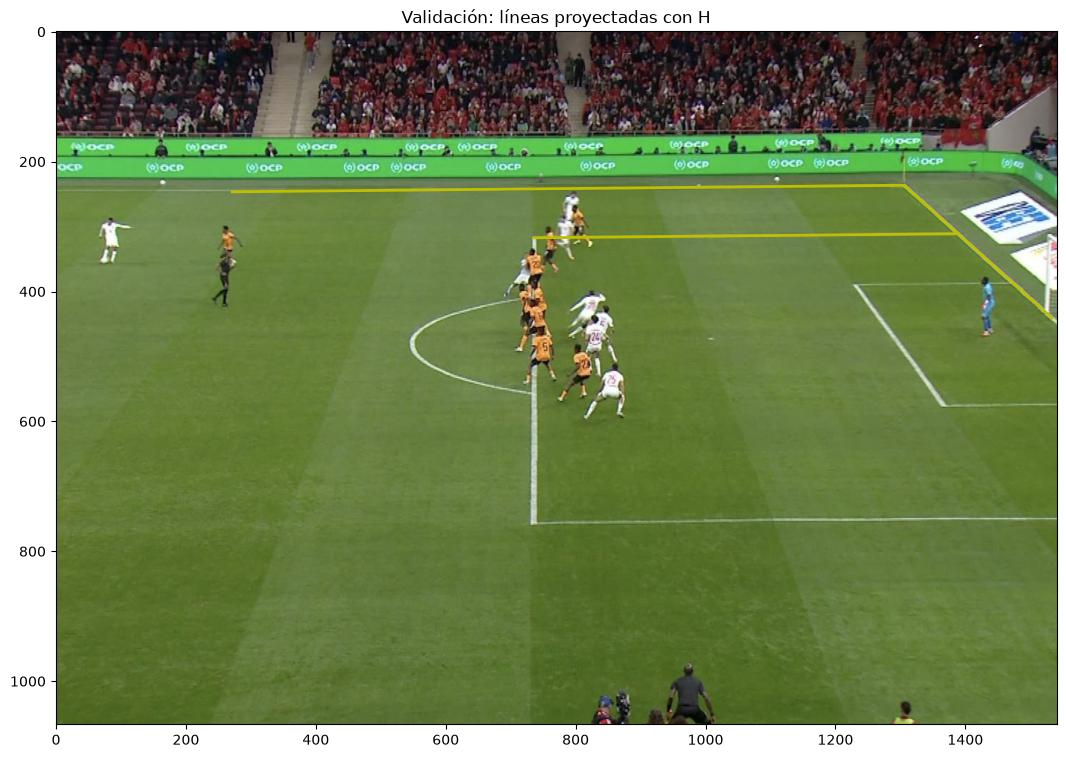

In [136]:
# Segmentos en la cancha (m), recortados para que queden dentro de la foto
segmentos = [
    [[105.0, 37.0], [105.0, 68.0]],    # línea de fondo
    [[75.0, 68.0], [105.0, 68.0]],     # banda de arriba
    [[88.5, 54.16], [105.0, 54.16]],   # lado de arriba del área grande
]

plt.figure(figsize=(14, 9))
plt.imshow(img_offside)
for segmento in segmentos:
    segmento_img = alc.aplicarHomografia(H_off, np.array(segmento))
    plt.plot(segmento_img[:, 0], segmento_img[:, 1], 'y-', linewidth=2)
plt.title('Validación: líneas proyectadas con H')
plt.show()

**Pies de los jugadores.** Marcamos a ojo en la foto el pie más adelantado (hacia el arco) de cada defensor (de naranja, N) y de cada atacante (de blanco, B):

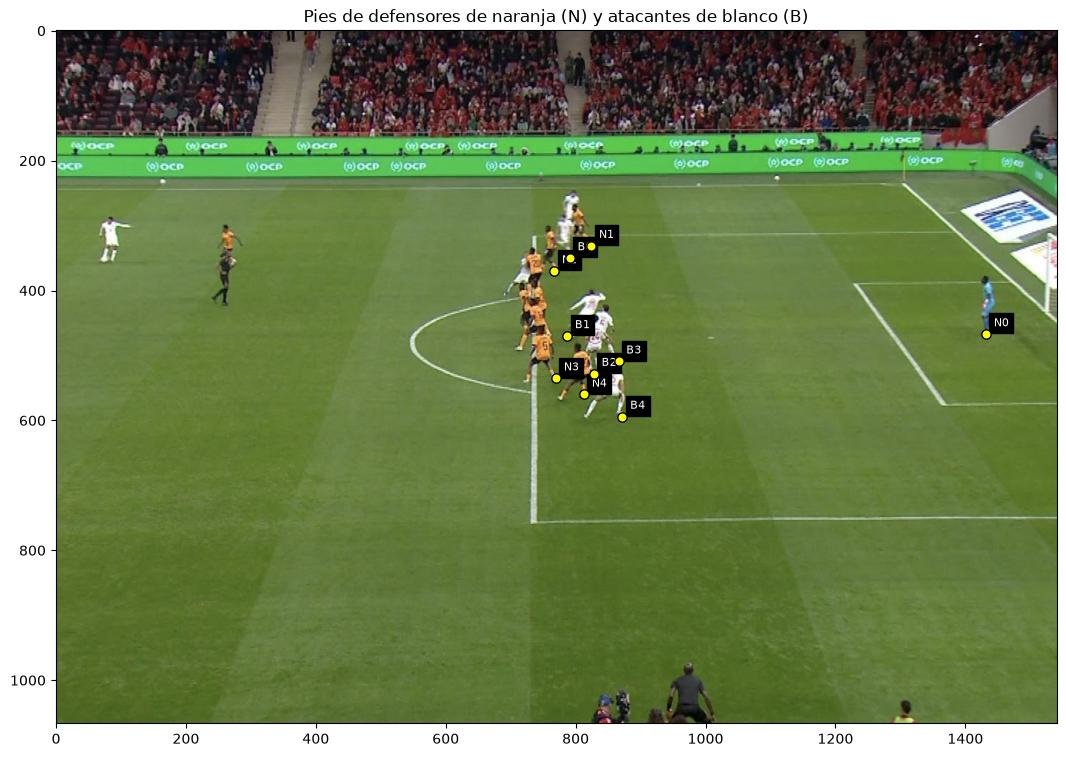

In [137]:
# Pie más adelantado de cada defensor (px)
pies_defensores_img = np.array([
    [1432.0, 467.0],  # N0: arquero
    [824.0,  331.0],  # N1: el de arriba del grupo
    [767.0,  370.0],  # N2: el del medio del grupo
    [770.0,  535.0],  # N3: el 5
    [813.0,  560.0],  # N4: el 22
])

# Pie más adelantado de cada atacante (px)
pies_atacantes_img = np.array([
    [791.0, 350.0],   # B0: el de arriba del grupo
    [787.0, 470.0],   # B1: el del medio
    [828.0, 528.0],   # B2: el 24
    [866.0, 509.0],   # B3: el que está a la derecha del 24 (pie posiblemente en el aire)
    [872.0, 594.0],   # B4: el 25
])

etiquetas_pies = []
for i in range(pies_defensores_img.shape[0]):
    etiquetas_pies.append(f'N{i}')
for i in range(pies_atacantes_img.shape[0]):
    etiquetas_pies.append(f'B{i}')

mostrar_puntos(img_offside, np.vstack((pies_defensores_img, pies_atacantes_img)), etiquetas=etiquetas_pies,
               titulo='Pies de defensores de naranja (N) y atacantes de blanco (B)', figsize=(14, 9))

**Último defensor.** Llevamos a la cancha con $\mathbf{H}^{-1}$ el pie más adelantado (hacia el arco) de cada defensor. El último defensor es el penúltimo contando al arquero: el de mayor $U$ sin contar al arquero, que es el de mayor $U$ de todos.

In [138]:
U_defensores = alc.aplicarHomografia(H_off_inv, pies_defensores_img)[:, 0]

# El arquero es el de mayor U; el último defensor, el de mayor U entre los demás
i_arquero = 0
for i in range(U_defensores.shape[0]):
    if U_defensores[i] > U_defensores[i_arquero]:
        i_arquero = i
i_ultimo = -1
for i in range(U_defensores.shape[0]):
    if i != i_arquero and (i_ultimo == -1 or U_defensores[i] > U_defensores[i_ultimo]):
        i_ultimo = i
U_ultimo = U_defensores[i_ultimo]
for i in range(U_defensores.shape[0]):
    print(f'Defensor N{i}: U = {U_defensores[i]:.2f} m')
print(f'Último defensor: N{i_ultimo}, U = {U_ultimo:.2f} m')

Defensor N0: U = 102.42 m
Defensor N1: U = 90.68 m
Defensor N2: U = 89.23 m
Defensor N3: U = 89.15 m
Defensor N4: U = 89.90 m
Último defensor: N1, U = 90.68 m


**Atacantes y recta del último defensor.** Un atacante está adelantado si su pie tiene $U$ mayor que el del último defensor. La recta paralela a la línea de fondo es $U = U_{\text{último}}$; la definimos en la cancha y la proyectamos con $\mathbf{H}$.

Atacante B0: U = 89.83 m, diferencia = -0.85 m -> habilitado
Atacante B1: U = 89.54 m, diferencia = -1.14 m -> habilitado
Atacante B2: U = 90.24 m, diferencia = -0.44 m -> habilitado
Atacante B3: U = 91.00 m, diferencia = +0.32 m -> ADELANTADO
Atacante B4: U = 90.87 m, diferencia = +0.19 m -> ADELANTADO


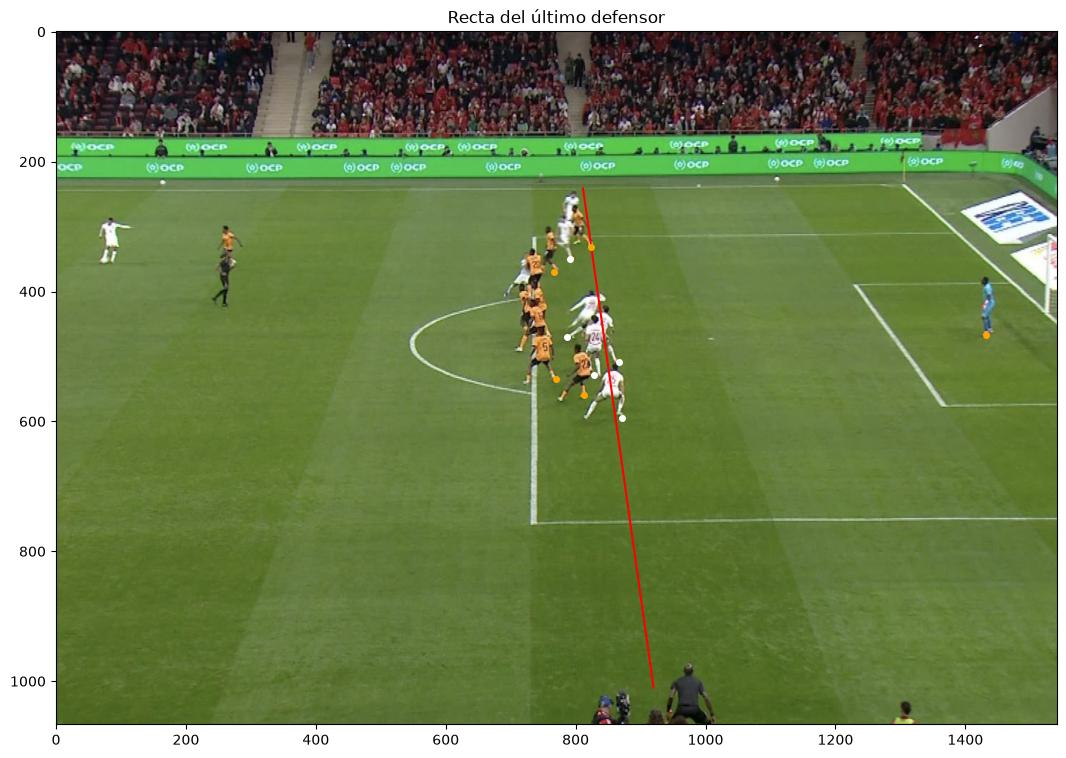

In [139]:
U_atacantes = alc.aplicarHomografia(H_off_inv, pies_atacantes_img)[:, 0]
for i in range(U_atacantes.shape[0]):
    diferencia = U_atacantes[i] - U_ultimo
    estado = 'ADELANTADO' if diferencia > 0 else 'habilitado'
    print(f'Atacante B{i}: U = {U_atacantes[i]:.2f} m, diferencia = {diferencia:+.2f} m -> {estado}')

# Recta U = U_ultimo en la cancha (recortada para que quede dentro de la foto), proyectada con H
recta_img = alc.aplicarHomografia(H_off, np.array([[U_ultimo, 3.0], [U_ultimo, 68.0]]))

plt.figure(figsize=(14, 9))
plt.imshow(img_offside)
plt.plot(recta_img[:, 0], recta_img[:, 1], 'r-', linewidth=1.5)
plt.plot(pies_defensores_img[:, 0], pies_defensores_img[:, 1], 'o', color='orange', markersize=4)
plt.plot(pies_atacantes_img[:, 0], pies_atacantes_img[:, 1], 'wo', markersize=4)
plt.title('Recta del último defensor')
plt.show()

**Conclusión.** El último defensor es el de arriba del grupo ($U \approx 90.68$ m). Dos atacantes quedan por delante de la recta, así que **hay fuera de juego**. La pelota está muy atrás (la tiene el jugador de la izquierda), así que esa condición también se cumple.

<hr style="border: none; border-top: 3px solid black;">

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

In [140]:
# Definimos algunas funciones auxiliares

def tiempo_en_segundos(nombre_foto):
    partes = nombre_foto.replace(".jpg", "").split("_")
    horas= int(partes[1])
    minutos= int(partes[2])
    segundos= int(partes[3])
    milisegundos = int(partes[4])
    tiempo = horas*3600 + minutos*60 + segundos + milisegundos/1000
    return tiempo

def metros_a_kmh(velocidad):
    return velocidad * 3.6

def velocidades_cada_n_frames(posiciones, tiempos,intervalo):
    velocidades = []
    tiempos_medios = [] #para graficar
    for i in range(0, len(posiciones) - intervalo, intervalo):
        j = i + intervalo
        #distancia recorrida entre las dos fotos
        desplazamiento = posiciones[j]-posiciones[i]
        distancia =alc.norma(desplazamiento, 2)
        #tiempo transcurrido entre las dos fotos
        tiempo_transcurrido = tiempos[j] - tiempos[i]
        #velocidad en m/s
        velocidad = distancia / tiempo_transcurrido
        velocidades.append(velocidad)
        #guardamos el tiempo medio entre ambos frames para realizar el gráfico
        tiempo_medio =(tiempos[i] + tiempos[j])/2
        tiempos_medios.append(tiempo_medio)
    return np.array(tiempos_medios), np.array(velocidades)

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [141]:
puntos_5a= pd.read_csv(os.path.join(DIR_SALGUERO, 'world_img_pts.csv'), sep=';')
puntos_5a

,pts,X,Y,Z,u_0,v_0,u_1,v_1,u_2,v_2,u_3,v_3
0,6,-4.0,3,0.0,281,474,255,490,469,581,446,563
1,36,4.0,0,0.0,889,521,1071,577,1147,653,1118,621
2,40,6.5,3,0.1,1139,493,1403,550,1425,625,1396,590
3,41,-5.0,14,0.1,418,385,437,377,627,485,600,466
4,42,-5.0,76,0.1,833,262,997,227,1094,357,1064,331


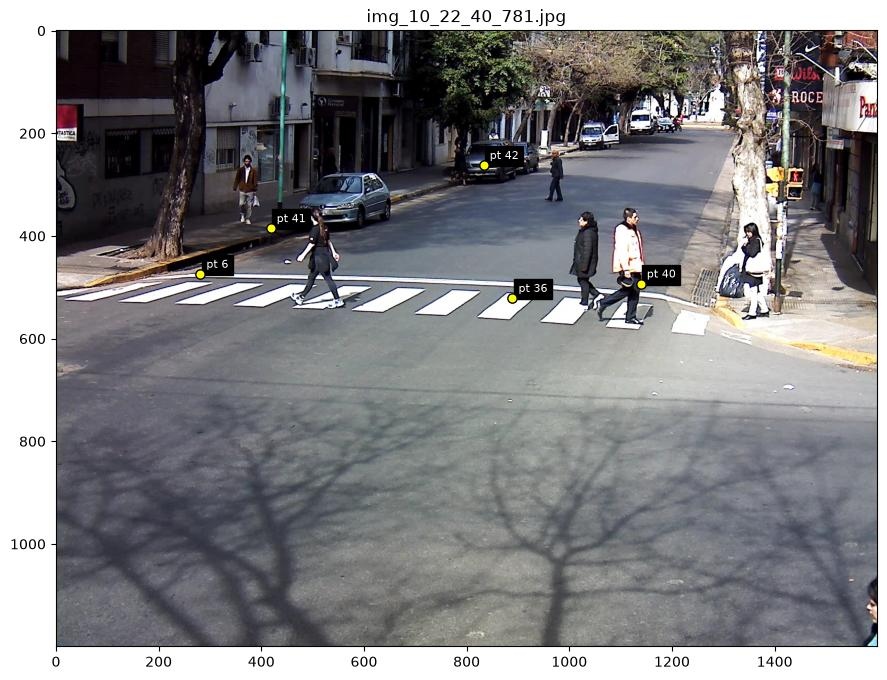

In [142]:
pts_img_list = []
for i in range(4):
    pts_img = puntos_5a[[f'u_{i}', f'v_{i}']]
    pts_img_list.append(pts_img)

pts_img_list = np.array(pts_img_list)

archivos = [
    'img_10_22_40_781.jpg',
    'img_10_23_46_794.jpg',
    'img_10_27_58_713.jpg',
    'img_10_28_40_718.jpg',
]

etiquetas_salguero = [f'pt {p}' for p in puntos_5a['pts']]

mostrar_puntos(
    leer_imagen(os.path.join(DIR_SALGUERO, archivos[0])),
    pts_img_list[0],
    etiquetas_salguero,
    titulo=archivos[0]
)

---

Notar que los puntos $Z$ no son todos $0$, los puntos 2,3 y 4 tienen $Z=0.1$, con lo cual no nos conviene usar el método de Zhang para coplanares. 

Pero tampoco tenemos 6 puntos, que es lo mínimo que precisamos para que con el método de Tsai nos aseguremos una solución única para $Qm=0$ (salvo factor un factor de escala) con $Q\in \R^{2n \times 12}$

In [143]:
print(puntos_5a.columns)
pts_3d_5a = puntos_5a[['X', 'Y', 'Z']]

pts_3d_5a

Index(['pts', 'X', 'Y', 'Z', 'u_0', 'v_0', 'u_1', 'v_1', 'u_2', 'v_2', 'u_3',
       'v_3'],
      dtype='str')


,X,Y,Z
0,-4.0,3,0.0
1,4.0,0,0.0
2,6.5,3,0.1
3,-5.0,14,0.1
4,-5.0,76,0.1


Ninguno de los dos métodos encaja perfectamente a los datos que tenemos para poder encontrar los parámetros extrínsicos y intrínsecos. Lo que podemos hacer es escojer uno, realizando una aproximación que nos permita aplicarlo y luego evaluar el error introducido.

Por simplicidad, escogemos probar con el método de Zhang, asumiendo $Z=0$ para todos los puntos, aprovechando que los $Z$ no nulos estan bastante cerca al $0$ y que tenemos $5>4$ puntos, siendo que para el método de Zhang precisabamos al menos 4 puntos para tambien asegurar una solución única no nula para $Qh=0$, con $Q\in \R^{2n \times 9}$ .
De esta manera, vamos a estimar $K$ y comparar las proyecciones de los puntos que nos da el modelo con las coordenadas 2D originales observadas en las cuatro fotos.

In [144]:
pts_2d_5a = puntos_5a[['X', 'Y']]
pts_2d_5a


,X,Y
0,-4.0,3
1,4.0,0
2,6.5,3
3,-5.0,14
4,-5.0,76


In [145]:
pts_2d_5a = np.array(pts_2d_5a)
H_list, K = alc.obtenerHsK_coplanar(pts_img_list, pts_2d_5a, restringir_K12=False)

R_list = []
t_list = []
for j in range(len(pts_img_list)):
    Rj, tj = alc.obtenerPose2D(H_list[j], K)
    R_list.append(Rj)
    t_list.append(tj)


Notar que el K obtenido tiene $\gamma = K_{12} \neq 0$ y $\alpha_u \neq \alpha_v$

In [146]:
print(f"K =\n{K}")

K =
[[2794.8048 1246.5262  325.524 ]
 [   0.      228.3802  213.4326]
 [   0.        0.        1.    ]]


Proyectamos de nuevo los puntos UVW usando la K y las R y t obtenidas para cada vista, para ver el error visualmente

----------------- img_10_22_40_781.jpg -----------------
K =
[[2794.8048 1246.5262  325.524 ]
 [   0.      228.3802  213.4326]
 [   0.        0.        1.    ]]

[R | t] =
[[  0.9315   0.3558  -0.0752 -15.4208]
 [  0.0041  -0.2169  -0.9762  39.6571]
 [ -0.3637   0.909   -0.2035  31.0912]]

Puntos uv proyectados =
[[ 270.908   465.8801]
 [ 891.3582  519.1567]
 [1131.0243  496.3107]
 [ 397.5898  396.187 ]
 [ 797.9983  265.0654]]

Puntos uv originales =
[[ 281  474]
 [ 889  521]
 [1139  493]
 [ 418  385]
 [ 833  262]]

Diferencias (en px) = 
[[10.092   8.1199]
 [ 2.3582  1.8433]
 [ 7.9757  3.3107]
 [20.4102 11.187 ]
 [35.0017  3.0654]]
RMSE: 20.137 píxeles


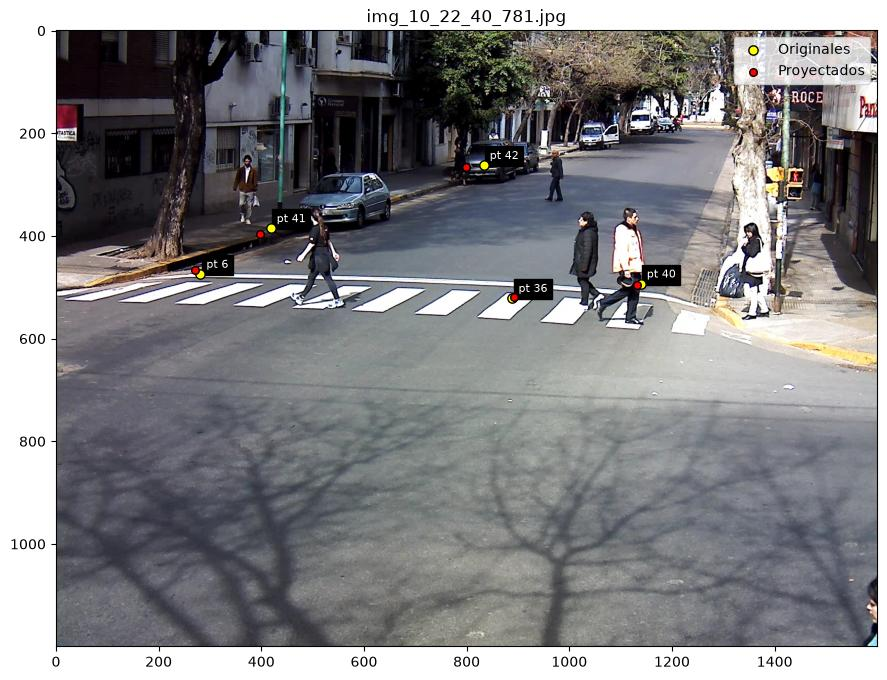

----------------- img_10_23_46_794.jpg -----------------
K =
[[2794.8048 1246.5262  325.524 ]
 [   0.      228.3802  213.4326]
 [   0.        0.        1.    ]]

[R | t] =
[[  0.8128   0.5019   0.2955 -14.0716]
 [  0.5153  -0.383   -0.7667  37.0579]
 [ -0.2716   0.7755  -0.57    25.8284]]

Puntos uv proyectados =
[[ 256.6552  477.7896]
 [1074.1452  574.5208]
 [1410.5287  553.2547]
 [ 463.4295  388.0422]
 [1053.0303  227.4833]]

Puntos uv originales =
[[ 255  490]
 [1071  577]
 [1403  550]
 [ 437  377]
 [ 997  227]]

Diferencias (en px) = 
[[ 1.6552 12.2104]
 [ 3.1452  2.4792]
 [ 7.5287  3.2547]
 [26.4295 11.0422]
 [56.0303  0.4833]]
RMSE: 28.966 píxeles


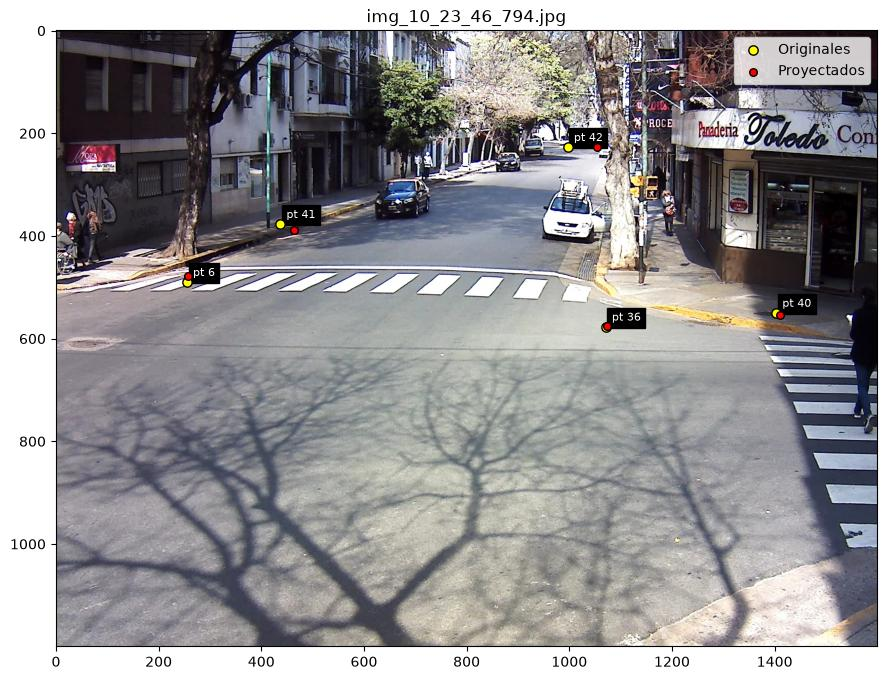

----------------- img_10_27_58_713.jpg -----------------
K =
[[2794.8048 1246.5262  325.524 ]
 [   0.      228.3802  213.4326]
 [   0.        0.        1.    ]]

[R | t] =
[[  0.9144   0.3101   0.2602 -20.0629]
 [  0.2216   0.1542  -0.9629  55.372 ]
 [ -0.3387   0.9381   0.0723  30.8215]]

Puntos uv proyectados =
[[ 462.6871  572.0739]
 [1149.4524  649.4589]
 [1422.3902  628.7569]
 [ 622.6774  495.1908]
 [1088.4949  358.3739]]

Puntos uv originales =
[[ 469  581]
 [1147  653]
 [1425  625]
 [ 627  485]
 [1094  357]]

Diferencias (en px) = 
[[ 6.3129  8.9261]
 [ 2.4524  3.5411]
 [ 2.6098  3.7569]
 [ 4.3226 10.1908]
 [ 5.5051  1.3739]]
RMSE: 7.921 píxeles


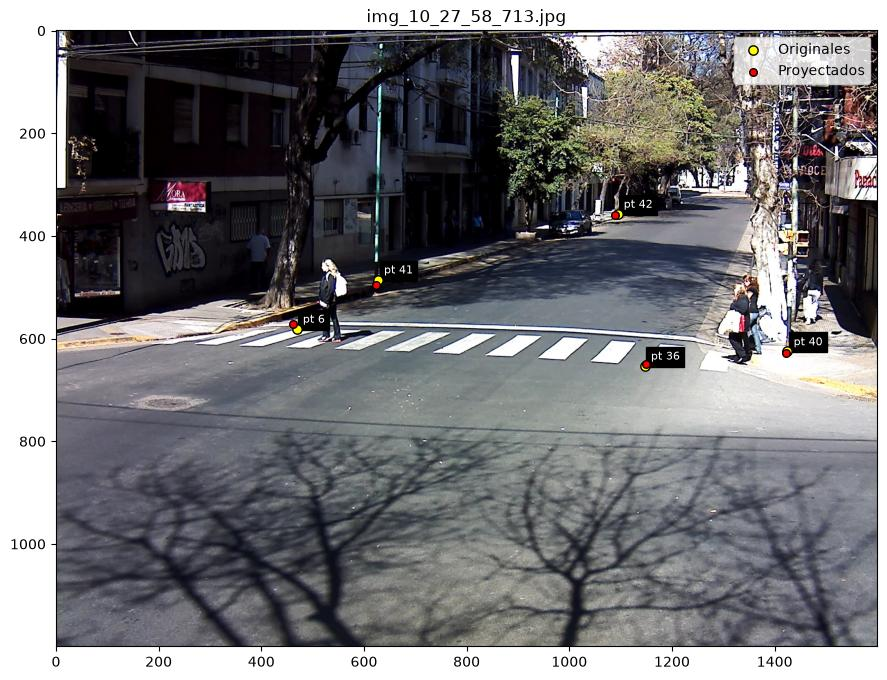

----------------- img_10_28_40_718.jpg -----------------
K =
[[2794.8048 1246.5262  325.524 ]
 [   0.      228.3802  213.4326]
 [   0.        0.        1.    ]]

[R | t] =
[[  0.9396   0.3416  -0.0183 -17.5314]
 [ -0.0259   0.0177  -0.9995  48.3453]
 [ -0.3412   0.9397   0.0255  28.5915]]

Puntos uv proyectados =
[[ 442.1436  551.3988]
 [1120.408   618.0844]
 [1384.8557  589.9255]
 [ 598.0914  468.9703]
 [1037.4362  325.0682]]

Puntos uv originales =
[[ 446  563]
 [1118  621]
 [1396  590]
 [ 600  466]
 [1064  331]]

Diferencias (en px) = 
[[ 3.8564 11.6012]
 [ 2.408   2.9156]
 [11.1443  0.0745]
 [ 1.9086  2.9703]
 [26.5638  5.9318]]
RMSE: 14.431 píxeles


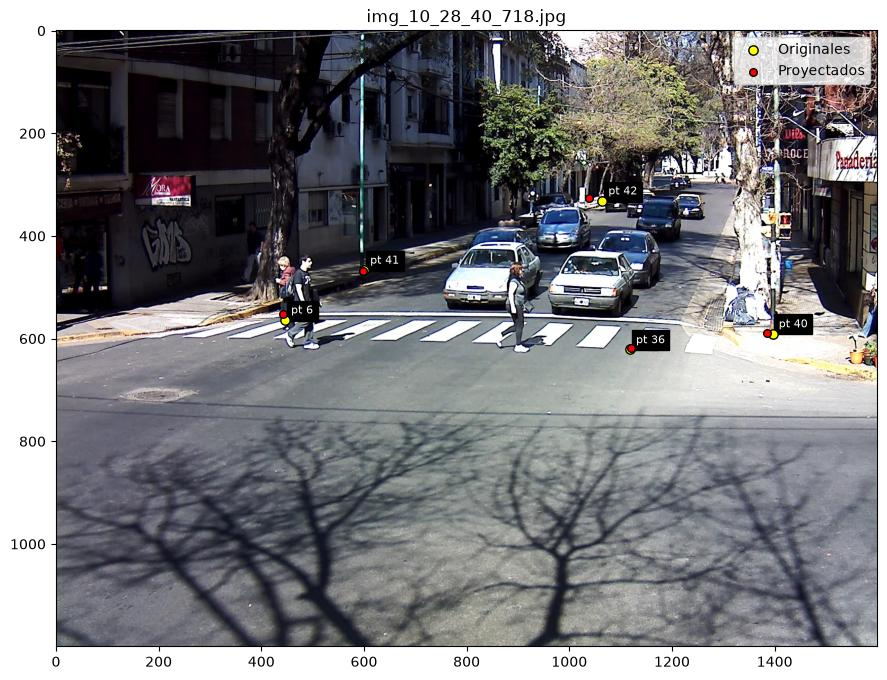

In [147]:
pts_3d_5a = np.array(pts_3d_5a)
for j in range(len(archivos)):
    pts_proyectados = alc.proyectarPuntosUVW(pts_3d_5a, K, R_list[j], t_list[j])
    rmse = alc.RMSE(pts_proyectados, pts_img_list[j])
    Rt_j = np.hstack((R_list[j], t_list[j].reshape(-1, 1)))

    print(f"----------------- {archivos[j]} -----------------")
    print(f"K =\n{K}\n")
    print(f"[R | t] =\n{Rt_j}\n")
    print(f"Puntos uv proyectados =\n{pts_proyectados}\n")
    print(f"Puntos uv originales =\n{pts_img_list[j]}\n")
    print(f"Diferencias (en px) = \n{np.abs(pts_img_list[j] - pts_proyectados)}")
    print(f"RMSE: {rmse:.3f} píxeles")

    mostrar_puntos(leer_imagen(os.path.join(DIR_SALGUERO, archivos[j])), pts_img_list[j],
                   etiquetas_salguero, pts_proyectados, archivos[j])

---

Para comparar los resultados obtenidos, vamos a calcular una nueva matriz $K$ imponiendo las restricciones:
$$
\gamma = 0, \qquad \alpha_u = \alpha_v
$$

A partir de esta matriz, recalculamos las poses $(R_j,t_j)$ de las cuatro vistas y proyectamos nuevamente los puntos 3D.
Luego, calculamos el RMSE de reproyección de cada foto y lo comparamos con el obtenido utilizando la matriz $K$ sin restricciones.

In [148]:

H_list_rest, K_rest = alc.obtenerHsK_coplanar(pts_img_list,pts_2d_5a,restringir_K12=True,restringir_K11_K22=True)

R_list_rest = []
t_list_rest = []
for j in range(len(pts_img_list)):
    Rj, tj = alc.obtenerPose2D(H_list_rest[j], K_rest)
    R_list_rest.append(Rj)
    t_list_rest.append(tj)

print(K_rest)


[[1511.5927    0.      325.5242]
 [   0.     1511.5927  213.4327]
 [   0.        0.        1.    ]]


Ahora buscamos las proyecciones en las 4 fotos y calculamos el rmse con la matriz  $K$ con restricciones.

----------------- img_10_22_40_781.jpg -----------------
K =
[[1511.5927    0.      325.5242]
 [   0.     1511.5927  213.4327]
 [   0.        0.        1.    ]]

[R | t] =
[[ 0.9785  0.2061 -0.0065  2.3765]
 [ 0.0003 -0.0332 -0.9994  3.3974]
 [-0.2062  0.978  -0.0326 17.6296]]

Puntos uv proyectados =
[[ 260.5593  446.395 ]
 [ 891.3582  519.1567]
 [1061.2253  465.1059]
 [ 342.7537  345.69  ]
 [ 539.25    225.9424]]

Puntos uv originales =
[[ 281  474]
 [ 889  521]
 [1139  493]
 [ 418  385]
 [ 833  262]]

Diferencias (en px) = 
[[ 20.4407  27.605 ]
 [  2.3582   1.8433]
 [ 77.7747  27.8941]
 [ 75.2463  39.31  ]
 [293.75    36.0576]]
RMSE con restricciones: 143.396 píxeles


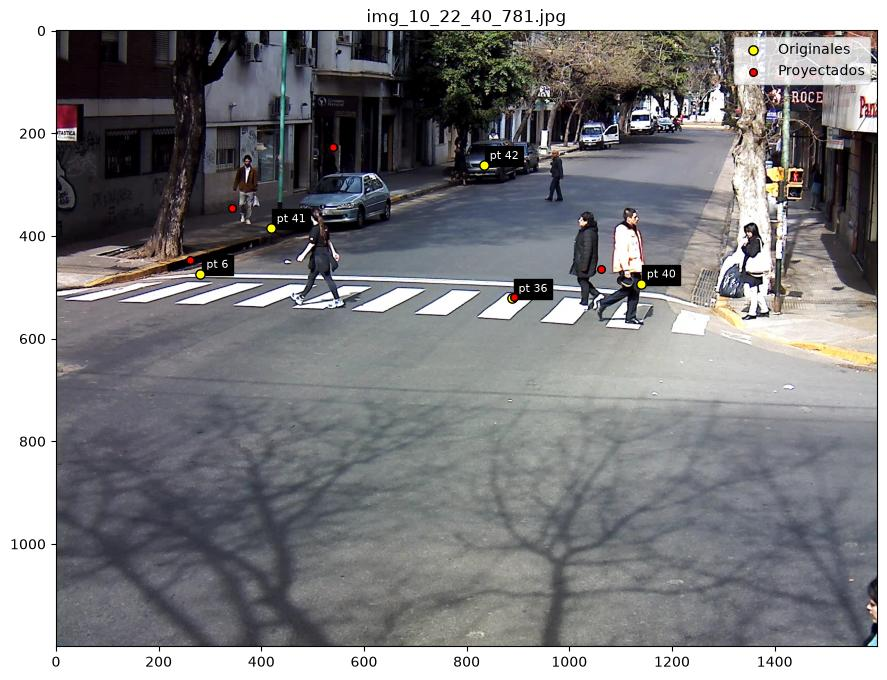

----------------- img_10_23_46_794.jpg -----------------
K =
[[1511.5927    0.      325.5242]
 [   0.     1511.5927  213.4327]
 [   0.        0.        1.    ]]

[R | t] =
[[ 0.9894  0.1425  0.0267  2.3313]
 [ 0.04   -0.0906 -0.9951  2.8736]
 [-0.1394  0.9856 -0.0954 13.2563]]

Puntos uv proyectados =
[[ 217.4747  433.5244]
 [1074.1452  574.5208]
 [1233.9029  486.3462]
 [ 291.8696  284.5587]
 [ 465.357   140.0383]]

Puntos uv originales =
[[ 255  490]
 [1071  577]
 [1403  550]
 [ 437  377]
 [ 997  227]]

Diferencias (en px) = 
[[ 37.5253  56.4756]
 [  3.1452   2.4792]
 [169.0971  63.6538]
 [145.1304  92.4413]
 [531.643   86.9617]]
RMSE con restricciones: 267.236 píxeles


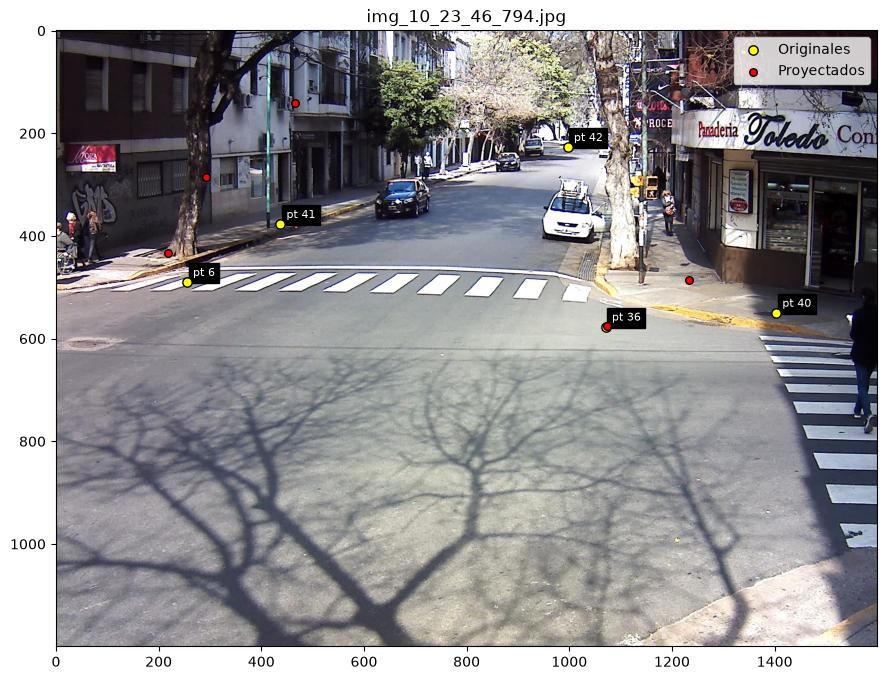

----------------- img_10_27_58_713.jpg -----------------
K =
[[1511.5927    0.      325.5242]
 [   0.     1511.5927  213.4327]
 [   0.        0.        1.    ]]

[R | t] =
[[ 0.9839  0.1776  0.0197  4.4995]
 [ 0.0176  0.0135 -0.9998  4.3935]
 [-0.1779  0.984   0.0101 16.1866]]

Puntos uv proyectados =
[[ 409.0457  545.723 ]
 [1149.4524  649.4589]
 [1286.2387  587.3284]
 [ 426.8826  428.7168]
 [ 540.7908  299.476 ]]

Puntos uv originales =
[[ 469  581]
 [1147  653]
 [1425  625]
 [ 627  485]
 [1094  357]]

Diferencias (en px) = 
[[ 59.9543  35.277 ]
 [  2.4524   3.5411]
 [138.7613  37.6716]
 [200.1174  56.2832]
 [553.2092  57.524 ]]
RMSE con restricciones: 274.989 píxeles


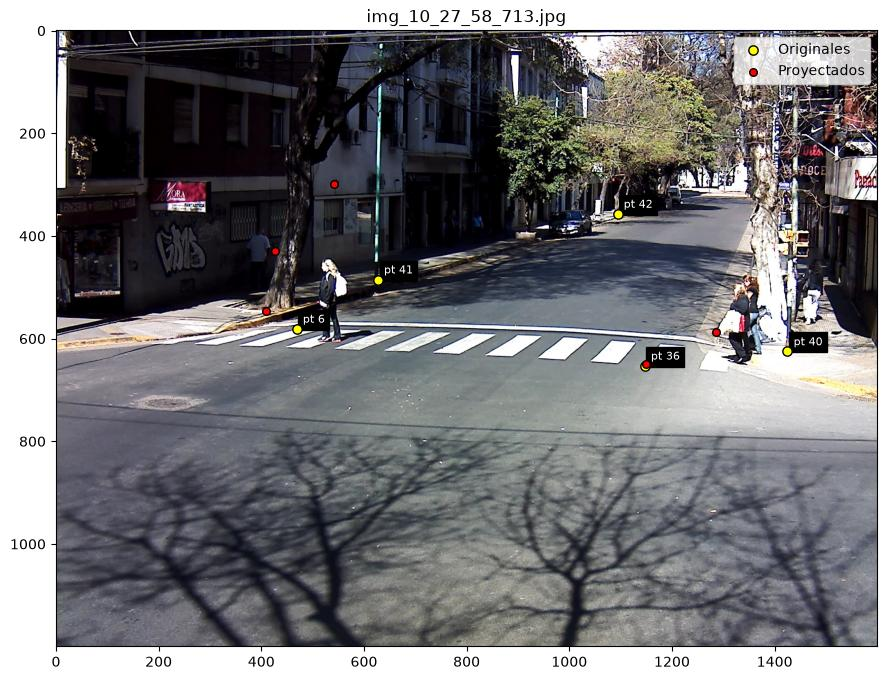

----------------- img_10_28_40_718.jpg -----------------
K =
[[1511.5927    0.      325.5242]
 [   0.     1511.5927  213.4327]
 [   0.        0.        1.    ]]

[R | t] =
[[ 0.9808  0.195  -0.0015  4.2603]
 [-0.0022  0.0035 -1.      4.1749]
 [-0.195   0.9808  0.0039 16.3422]]

Puntos uv proyectados =
[[ 394.994   529.4262]
 [1120.408   618.0844]
 [1266.867   554.9671]
 [ 427.0901  414.7591]
 [ 558.8068  285.0674]]

Puntos uv originales =
[[ 446  563]
 [1118  621]
 [1396  590]
 [ 600  466]
 [1064  331]]

Diferencias (en px) = 
[[ 51.006   33.5738]
 [  2.408    2.9156]
 [129.133   35.0329]
 [172.9099  51.2409]
 [505.1932  45.9326]]
RMSE con restricciones: 249.599 píxeles


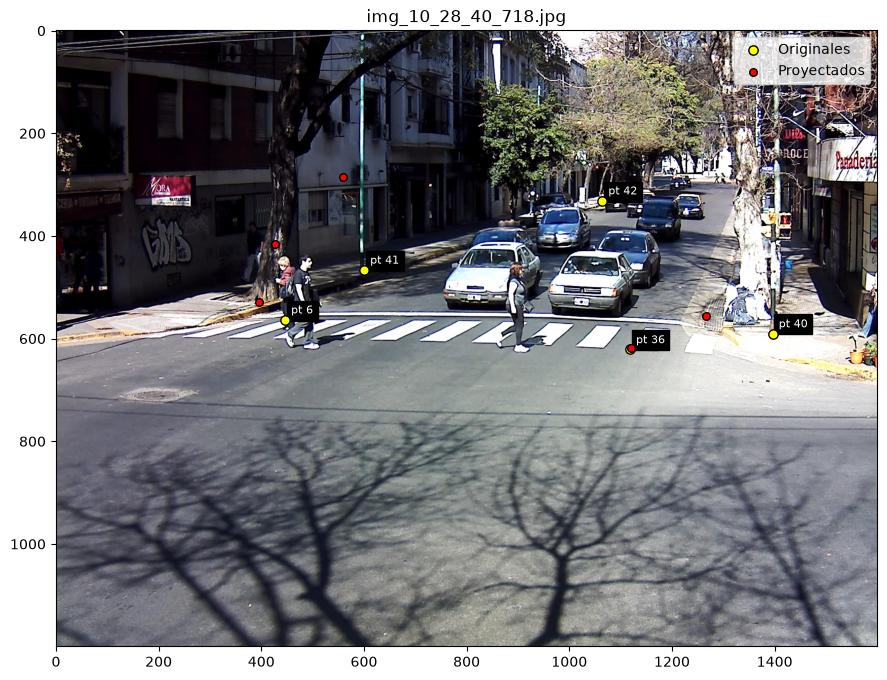

In [149]:
for j in range(len(archivos)):
    pts_proyectados = alc.proyectarPuntosUVW(pts_3d_5a, K_rest, R_list_rest[j], t_list_rest[j])
    rmse = alc.RMSE(pts_proyectados, pts_img_list[j])
    Rt_j = np.hstack((R_list_rest[j], t_list_rest[j].reshape(-1, 1)))

    print(f"----------------- {archivos[j]} -----------------")
    print(f"K =\n{K_rest}\n")
    print(f"[R | t] =\n{Rt_j}\n")
    print(f"Puntos uv proyectados =\n{pts_proyectados}\n")
    print(f"Puntos uv originales =\n{pts_img_list[j]}\n")
    print(f"Diferencias (en px) = \n{np.abs(pts_img_list[j] - pts_proyectados)}")
    print(f"RMSE con restricciones: {rmse:.3f} píxeles")

    mostrar_puntos(leer_imagen(os.path.join(DIR_SALGUERO, archivos[j])), pts_img_list[j],
                   etiquetas_salguero, pts_proyectados, archivos[j])

Observamos que al imponer las restricciones $K_{12}=0$ y $K_{11}=K_{22}$, el error de reproyección aumentó respecto del modelo sin restricciones.
Esto creemos que se debe a que las homografías fueron calculadas a partir de las correspondencias originales y permanecen iguales, mientras que la matriz intrínseca $K$ la modificamos al imponer las restricciones.

Por lo tanto, tenemos que la relación
$$
H\sim K[r_1\quad r_2\quad t]
$$

puede dejar de satisfacerse de manera consistente con una matriz de rotación válida, por lo que podemos decir que esta puede ser lo que produzca un RMSE más grande. 


**b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.**

In [150]:
correspondencias=pd.read_csv(os.path.join(DIR_SALGUERO, 'gs_10_09_point_correspondences_v5.txt'), sep=r'\s+', header=None).to_numpy()             
indices = correspondencias[0, :]

puntos_3d_5b = alc.traspuesta(correspondencias[1:4, :])
puntos_2d_5b = alc.traspuesta(correspondencias[4:6, :])

Observamos que si bien tenemos más de 6 puntos , en particular 51 puntos, no podemos aplicar el algoritmo de Tsai, pues como indicamos en el ejercicio 1.a, para utilizar este método los puntos no pueden ser todos coplanares, y en este caso notamos que todos los puntos 3D tienen $Z=0$.

In [151]:
np.unique(puntos_3d_5b[:, 2])

array([0.])

Por lo tanto, vamos a utilizar nuevamente el algoritmo de Zhang. Para recuperar la pose $(R,t)$ de la cámara, utilizamos las matrices intrínsecas estimadas en el ejercicio 5.a, tanto con restricciones como sin ellas, a partir de la relación:

$$
H\sim K[r_1\quad r_2\quad t]
$$



In [152]:
#estimamos R,t con K sin restricciones del 5.a
puntos_plano = puntos_3d_5b[:, :2]
H = alc.resolverDLT2D(puntos_2d_5b, puntos_plano)
R, t = alc.obtenerPose2D(H, K)

print("H:", H)
print("R:", R)
print("t:", t)

R_rest, t_rest = alc.obtenerPose2D(H, K_rest)

print("R restringida:", R_rest)
print("t restringida:", t_rest)

H: [[ 36.5963  20.9792 233.781 ]
 [ -0.4632   3.5017 232.614 ]
 [ -0.003    0.0191   0.4551]]
R: [[ 0.9725  0.2312  0.0282]
 [ 0.0597 -0.1303 -0.9897]
 [-0.2251  0.9641 -0.1406]]
t: [-17.3813  44.0737  33.8166]
R restringida: [[ 0.9926  0.121   0.0023]
 [ 0.0048 -0.0208 -0.9998]
 [-0.121   0.9924 -0.0212]]
t restringida: [ 2.2615  3.5782 18.1713]


Ahora reproyectamos los 51 puntos usando ambas poses y comparamos sus RMSE.

In [153]:
# Proyección con K sin restricciones
proyectados_5b = alc.proyectarPuntosUVW(
    puntos_3d_5b, K, R, t
)

rmse_5b = alc.RMSE(proyectados_5b, puntos_2d_5b)

# Proyección con K restringida
proyectados_rest_5b = alc.proyectarPuntosUVW(
    puntos_3d_5b, K_rest, R_rest, t_rest
)

rmse_rest_5b = alc.RMSE(
    proyectados_rest_5b, puntos_2d_5b
)

print(f"RMSE sin restricciones: {rmse_5b:.3f} píxeles")
print(f"RMSE con restricciones: {rmse_rest_5b:.3f} píxeles")
#da muy mal



RMSE sin restricciones: 92.942 píxeles
RMSE con restricciones: 542.998 píxeles


**c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.**

In [154]:
#Seleccionamos manualmente los puntos que referencian el taxi, la camioneta y la señora en las 46 fotos

puntos_salguero = pd.read_csv(os.path.join(DIR_GS_DATASET, 'puntos_movimiento_nuevo.csv'), sep=",")
display(puntos_salguero.head())


,foto,u_senora,v_senora,u_camioneta,v_camioneta,u_taxi,v_taxi
0,img_10_18_47_351.jpg,428,501,1011,259,946,269
1,img_10_18_47_461.jpg,458,500,1009,259,945,267
2,img_10_18_47_554.jpg,489,497,1009,259,937,268
3,img_10_18_47_679.jpg,491,498,1010,262,938,271
4,img_10_18_47_835.jpg,496,501,1011,262,936,273


Como la foto del ejercicio 5.b (img_10_18_47_351.jpg) forma parte de las 46 fotos en gs_dataset, y la pose de la cámara es la misma en todas las fotografías, podemos utilizar la homografía calculada en el 5.b

In [155]:
#invertimos la homografía del 5.b
H_inv = alc.inversa(H)

pts_senora = puntos_salguero[["u_senora", "v_senora"]].to_numpy()
pts_camioneta = puntos_salguero[["u_camioneta", "v_camioneta"]].to_numpy()
pts_taxi = puntos_salguero[["u_taxi", "v_taxi"]].to_numpy()

#transformamos las coordenadas de píxeles a metros
pos_senora = alc.aplicarHomografia(H_inv, pts_senora)
pos_camioneta = alc.aplicarHomografia(H_inv, pts_camioneta)
pos_taxi = alc.aplicarHomografia(H_inv, pts_taxi)

#calculamos las distancias recorridas por:
#señora:
desplazamiento_senora = pos_senora[-1] - pos_senora[0]
distancia_senora = alc.norma(desplazamiento_senora, 2)
#taxi:
desplazamiento_taxi = pos_taxi[-1] - pos_taxi[0]
distancia_taxi = alc.norma(desplazamiento_taxi, 2)
#camioneta:
desplazamiento_camioneta = pos_camioneta[-1] - pos_camioneta[0]
distancia_camioneta = alc.norma(desplazamiento_camioneta, 2)

tiempos=[]
for nombre_foto in puntos_salguero["foto"]:
    tiempo= tiempo_en_segundos(nombre_foto)
    tiempos.append(tiempo)

tiempos= np.array(tiempos)
tiempos= tiempos - tiempos[0] #tomamos la primera foto como tiempo 0
print(tiempos)
#Si queremos calcular la velocidad media tenemos que:
v_media_senora=distancia_senora/tiempos[-1]
v_media_taxi=distancia_taxi/tiempos[-1]
v_media_camioneta=distancia_camioneta/tiempos[-1]
print(v_media_senora, v_media_taxi, v_media_camioneta) #en metros por segundo

print("Señora:", metros_a_kmh(v_media_senora), "km/h")
print("Taxi:", metros_a_kmh(v_media_taxi), "km/h")
print("Camioneta:", metros_a_kmh(v_media_camioneta), "km/h")



[0.    0.11  0.203 0.328 0.484 0.531 0.671 0.812 0.858 0.999 1.124 1.373
 1.467 1.654 1.748 1.935 1.966 2.106 2.231 2.309 2.434 2.528 2.637 2.777
 2.855 2.949 3.12  3.183 3.323 3.432 3.542 3.635 3.822 3.9   3.994 4.119
 4.212 4.306 4.493 4.524 4.649 4.758 4.868 4.961 5.102 5.195]
1.3738009296208247 12.805667112626205 12.692106004518616
Señora: 4.945683346634969 km/h
Taxi: 46.10040160545434 km/h
Camioneta: 45.691581616267015 km/h


Al analizar la velocidad a lo largo del tiempo, para reducir el efecto del ruido producido por posibles errores al marcar manualmente las posiciones de los objetos(señora, taxi, y camioneta) en las imágenes, estimamos sus velocidades utilizando intervalos de 5 frames.
Para cada intervalo, calculamos el desplazamiento euclídeo entre las posiciones inicial y final, y lo dividimos por el tiempo transcurrido entre ambas fotos.
Las velocidades las calculamos primero en m/s y luego las pasamos a km/h para representar su evolución en el tiempo en el gráfico.


Velocidades señora: [2.7061 0.9749 1.6933 1.7376 1.4153 1.2267 1.449  1.5627 0.9838]
Velocidades taxi: [ 7.8088  9.2166  7.1499 14.932  17.3605 16.5983 14.2638 18.9293 12.2751]
Velocidades camioneta: [11.932   5.852   5.2582 16.6188 18.5659  9.1984 14.3146 21.2346 16.5818]


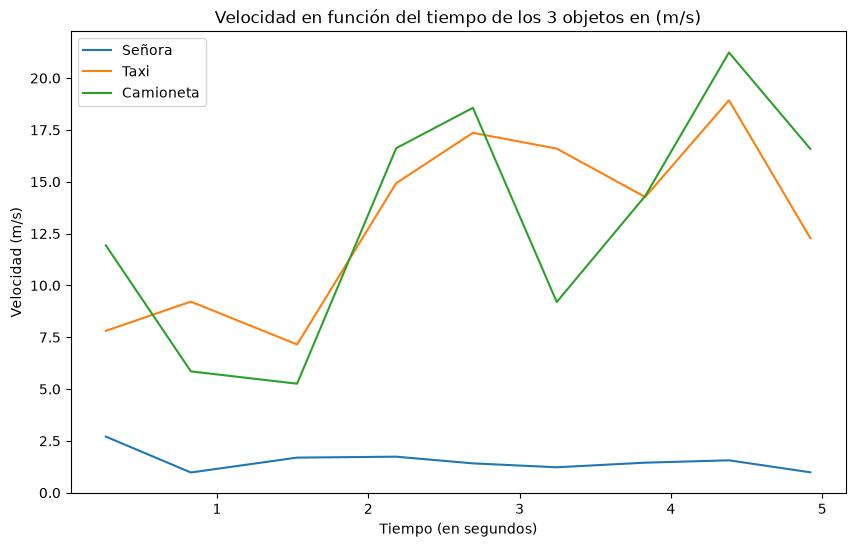

In [156]:
t_senora, v_senora = velocidades_cada_n_frames(pos_senora, tiempos, 5)
t_taxi, v_taxi = velocidades_cada_n_frames(pos_taxi, tiempos,5)
t_camioneta, v_camioneta = velocidades_cada_n_frames(pos_camioneta, tiempos,5)

print("Velocidades señora:", v_senora)
print("Velocidades taxi:", v_taxi)
print("Velocidades camioneta:", v_camioneta)
plt.figure(figsize=(10, 6))

plt.plot(t_senora, v_senora, label="Señora")
plt.plot(t_taxi, v_taxi, label="Taxi")
plt.plot(t_camioneta, v_camioneta, label="Camioneta")

plt.title("Velocidad en función del tiempo de los 3 objetos en (m/s)")
plt.xlabel("Tiempo (en segundos)")
plt.ylabel("Velocidad (m/s)")
plt.legend()
plt.show()

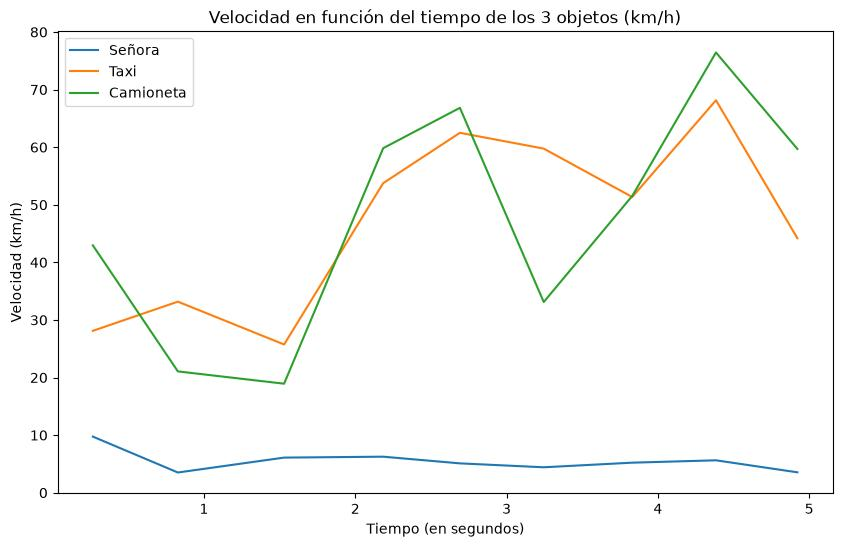

Intervalo: 0 a 5 Velocidad: 42.955122858189476 km/h
Intervalo: 5 a 10 Velocidad: 21.067283178940507 km/h
Intervalo: 10 a 15 Velocidad: 18.929551532921966 km/h
Intervalo: 15 a 20 Velocidad: 59.827729460671 km/h
Intervalo: 20 a 25 Velocidad: 66.83709766469289 km/h
Intervalo: 25 a 30 Velocidad: 33.11418457172998 km/h
Intervalo: 30 a 35 Velocidad: 51.53246247397264 km/h
Intervalo: 35 a 40 Velocidad: 76.4446547449879 km/h
Intervalo: 40 a 45 Velocidad: 59.694589425508305 km/h


In [157]:
#si queremos el gráfico en km/h , también lo podemos calcular aunque va a dar exactamente igual, solo cambian los valores del eje y
v_senora_kmh = metros_a_kmh(v_senora)
v_taxi_kmh = metros_a_kmh(v_taxi)
v_camioneta_kmh = metros_a_kmh(v_camioneta)
plt.figure(figsize=(10, 6))
plt.plot(t_senora, v_senora_kmh, label="Señora")
plt.plot(t_taxi, v_taxi_kmh, label="Taxi")
plt.plot(t_camioneta, v_camioneta_kmh, label="Camioneta")

plt.title("Velocidad en función del tiempo de los 3 objetos (km/h)")
plt.xlabel("Tiempo (en segundos)")
plt.ylabel("Velocidad (km/h)")
plt.legend()
plt.show()
plt.show()

for i in range(len(v_camioneta_kmh)):
    print("Intervalo:", i*5, "a", (i+1)*5,
          "Velocidad:", v_camioneta_kmh[i], "km/h")

Posible interpretación:
Observamos que alrededor del segundo 3, tanto el taxi como la camioneta mostraron una disminución en sus velocidades estimadas. Luego, cerca del segundo 4, estas vuelven a aumentar y posteriormente disminuyen.
Consideramos que una posible explicación es que ambos vehículos reducieron su velocidad al aproximarse a la senda peatonal para evitar chocar con la señora que estaba cruzando, y cuando vieron que la señora estaba por finalizar el cruce, aumentaron de nuevo su velocidad.

<hr style="border: none; border-top: 3px solid black;">


### Ejercicio 6 - Aterrizaje suave

**En este ejercicio vamos a implementar el método de POSIT para el cálculo de la pose de la cámara con respecto a una mira de tipo H para el aterrizaje de un drone. Se aporta la matriz de parámetros intrínsecos de la cámara ($\texttt{K.csv}$) y la lista de puntos reales con sus coordenadas en metros. POSIT aporta 2 soluciones para un problema coplanar; simplificamos el algoritmo seleccionando en cada iteración la solución que minimice el error cuadrático medio. Si en una solución no todos los puntos quedan frente a la cámara ($z$ negativo), esa solución no se toma en cuenta.**

**a) Elegir convenientemente los puntos a etiquetar en la imagen capturada por la cámara del drone ($\texttt{row\_00248.png}$) para calcular la pose.**

Etiquetamos los mismos 5 puntos de $\texttt{object\_points.csv}$, en el mismo orden: el centro de la H ($M_0$, que POSIT usa como punto de referencia) y los 4 extremos exteriores. Son puntos fáciles de ubicar en la foto (esquinas bien marcadas) y están bien separados. Todos tienen $W = 0$, así que estamos en el caso coplanar de POSIT.

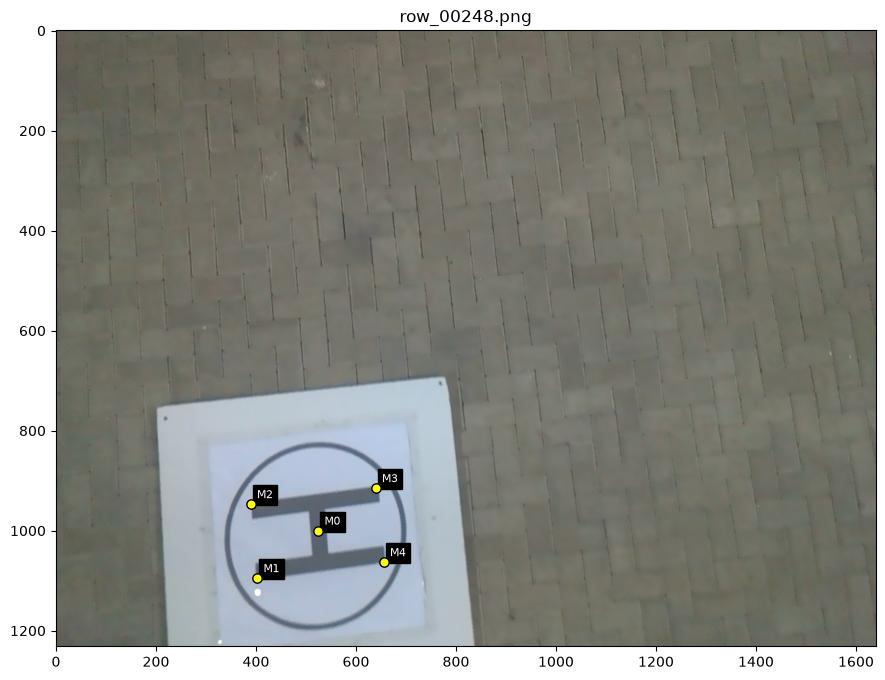

In [158]:
matriz_K = pd.read_csv(os.path.join(DIR_HELI, 'K.csv'), sep=';', header=None).to_numpy()
puntos_3d = pd.read_csv(os.path.join(DIR_HELI, 'object_points.csv'), sep=';', header=0, index_col=0).to_numpy(dtype=float)

img_heli = leer_imagen(os.path.join(DIR_HELI, 'row_00248.png'))

# Puntos 2D marcados en la imagen
puntos_2d = np.array([
    [525, 1000],  #Centro M0
    [403, 1095],  #Sup izq
    [390, 947],   #Sup der
    [640, 915],   #Inf der
    [656, 1063]   #Inf izq
])
etiquetas_heli = ['M0', 'M1', 'M2', 'M3', 'M4']

mostrar_puntos(img_heli, puntos_2d, etiquetas_heli, titulo='row_00248.png')

**b) Implementar la función $\texttt{calculoLambdaMu(I0, J0)}$ que devuelve $\lambda$ y $\mu$ de la ecuación 16.**

Como los puntos son coplanares, la matriz $A$ (filas $M_i - M_0$) tiene rango 2 y los sistemas

$$A\mathbf{I} = \mathbf{b}_u, \qquad A\mathbf{J} = \mathbf{b}_v$$

tienen infinitas soluciones, entonces se precisan definir restricciones adicionales.

Definimos $\mathbf{I}_0$ y $\mathbf{J}_0$ como las soluciones por cuadrados mínimos (de norma mínima) de esos sistemas:

$$\mathbf{I}_0 = A^{+}\mathbf{b}_u, \qquad \mathbf{J}_0 = A^{+}\mathbf{b}_v,$$

donde $A^{+}$ es la pseudoinversa de $A$. Sea $\mathbf{n}$ un vector unitario normal al plano del objeto (su sentido puede tomarse en cualquiera de las dos direcciones), es decir, un vector del núcleo de $A$: $A\mathbf{n} = 0$. Entonces las soluciones posibles pueden escribirse como

$$\mathbf{I} = \mathbf{I}_0 + \lambda \mathbf{n}, \qquad \mathbf{J} = \mathbf{J}_0 + \mu \mathbf{n}.$$

Para que $\mathbf{I}$ y $\mathbf{J}$ correspondan a los dos primeros ejes de una rotación, deben ser perpendiculares y tener el mismo módulo:

$$\text{(1)}\quad \mathbf{I}^T\mathbf{J} = 0, \qquad\qquad \text{(2)}\quad \|\mathbf{I}\| = \|\mathbf{J}\|.$$

Estas dos restricciones permiten calcular los escalares $\lambda$ y $\mu$. Como $\mathbf{n}$ es unitario y ortogonal a $\mathbf{I}_0$ y $\mathbf{J}_0$ (que están en el espacio de filas de $A$), la condición (1) lleva a $\lambda\mu = -\mathbf{I}_0^T\mathbf{J}_0$ y la (2) se cumple si $\lambda^2 - \mu^2 = \|\mathbf{J}_0\|^2 - \|\mathbf{I}_0\|^2$. Esto nos lleva a

$$C^2 = (\lambda + i\mu)^2 = (\lambda^2 - \mu^2) + 2i\lambda\mu = \left(\|\mathbf{J}_0\|^2 - \|\mathbf{I}_0\|^2\right) - 2i\,\mathbf{I}_0^T\mathbf{J}_0,$$

así que $\texttt{calculoLambdaMu}$ calcula la parte real e imaginaria de $C^2$ y le saca la raíz cuadrada con $\texttt{raicesCuadradasDeCCuadrado}$. En general aparecen dos soluciones, $(\lambda, \mu)$ y $(-\lambda, -\mu)$, que corresponden a dos poses simétricas compatibles con una aproximación ortográfica escalada.

Lo probamos con la primera iteración de POSIT ($\varepsilon_i = 0$) y verificamos que $\mathbf{I}$ y $\mathbf{J}$ queden ortogonales y de igual norma:

In [159]:
A_heli = alc.construir_A(puntos_3d)
coords_heli = alc.centrar_coords(puntos_2d, matriz_K)
n_heli = alc.nucleo(A_heli)[:, 0]
n_heli = n_heli / alc.norma(n_heli, 2)

# Primera iteración: epsilon_i = 0
eps0 = np.zeros(puntos_3d.shape[0])
pseudo_inv_A_heli = alc.pseudoinversa(A_heli)
I0 = alc.calcularAx(pseudo_inv_A_heli, alc.calcular_b(coords_heli, eps0, "u"))
J0 = alc.calcularAx(pseudo_inv_A_heli, alc.calcular_b(coords_heli, eps0, "v"))

lambd, mu = alc.calculoLambdaMu(I0, J0)
print(f'lambda = {lambd:.4f}, mu = {mu:.4f}')

I1 = I0 + lambd * n_heli
J1 = J0 + mu * n_heli
print('I^T J =', alc.producto_interno(I1, J1))
print('||I|| =', alc.norma(I1, 2), ' ||J|| =', alc.norma(J1, 2))

lambda = 86.0131, mu = 56.2377
I^T J = 0.0
||I|| = 429.90147781550655  ||J|| = 429.90147781550655


**c) Implementar la función $\texttt{calcularSalidaPOSIT(Is, Js, fx, m0, M0)}$ que devuelve una pose correspondiente a una posible solución $\mathbf{i}, \mathbf{j}, \mathbf{k}, Z_0, \mathbf{R}, \mathbf{t}$ de $(I_s, J_s)$.**

A partir de $\mathbf{I}$ y $\mathbf{J}$ normalizamos para obtener las dos primeras filas de $\mathbf{R}$, completamos con el producto vectorial y recuperamos la profundidad de $M_0$:

$$\mathbf{i} = \frac{\mathbf{I}}{\|\mathbf{I}\|}, \qquad \mathbf{j} = \frac{\mathbf{J}}{\|\mathbf{J}\|}, \qquad \mathbf{k} = \mathbf{i} \times \mathbf{j}, \qquad Z_0 = \frac{f_x}{\|\mathbf{I}\|}, \qquad \mathbf{R} = \begin{bmatrix} \mathbf{i}^T \\ \mathbf{j}^T \\ \mathbf{k}^T \end{bmatrix}.$$

Con $m_0 = (x_0, y_0)$ centrado en el punto principal, la posición de $M_0$ en la cámara es $T = \left(\frac{Z_0}{f_x}x_0,\ \frac{Z_0}{f_x}y_0,\ Z_0\right)$ y la traslación es $\mathbf{t} = T - \mathbf{R}M_0$.

Calculamos las dos poses candidatas de la primera iteración, una con $(\lambda, \mu)$ y otra con $(-\lambda, -\mu)$:

In [160]:
fx = matriz_K[0, 0]
m0 = coords_heli[0]
M0 = puntos_3d[0]

i_1, j_1, k_1, Z0_1, R_1, t_1 = alc.calcularSalidaPOSIT(I0 + lambd * n_heli, J0 + mu * n_heli, fx, m0, M0)
i_2, j_2, k_2, Z0_2, R_2, t_2 = alc.calcularSalidaPOSIT(I0 - lambd * n_heli, J0 - mu * n_heli, fx, m0, M0)

print(f'Solución 1:\nR =\n{R_1}\nt = {t_1}, Z0 = {Z0_1:.4f}\n')
print(f'Solución 2:\nR =\n{R_2}\nt = {t_2}, Z0 = {Z0_2:.4f}')

Solución 1:
R =
[[-0.0964 -0.975   0.2001]
 [-0.9836  0.1241  0.1308]
 [-0.1524 -0.1842 -0.971 ]]
t = [-0.685   0.8944  4.4031], Z0 = 4.4031

Solución 2:
R =
[[-0.0964 -0.975  -0.2001]
 [-0.9836  0.1241 -0.1308]
 [ 0.1524  0.1842 -0.971 ]]
t = [-0.685   0.8944  4.4031], Z0 = 4.4031


**d) Implementar la función $\texttt{evaluarPose(R, t, obj\_vecs, img\_vecs, K)}$ que devuelve la cantidad de proyecciones válidas de $\texttt{obj\_vecs}$, y el RMS obtenido con respecto a las posiciones originales en $\texttt{img\_vecs}$.**

Para cada punto calculamos sus coordenadas en la cámara $\mathbf{R}M_i + \mathbf{t}$. Es válido si queda delante de la cámara ($Z > 0$); en ese caso lo proyectamos con $\mathbf{K}$ y dividimos por la tercera coordenada. El RMSE se calcula sobre las proyecciones válidas. Evaluamos las dos poses candidatas del inciso anterior:

In [161]:
validos_1, rmse_1 = alc.evaluarPose(R_1, t_1, puntos_3d, puntos_2d, matriz_K)
validos_2, rmse_2 = alc.evaluarPose(R_2, t_2, puntos_3d, puntos_2d, matriz_K)
print(f'Solución 1: {validos_1} proyecciones válidas, RMSE = {rmse_1:.3f} px')
print(f'Solución 2: {validos_2} proyecciones válidas, RMSE = {rmse_2:.3f} px')

Solución 1: 5 proyecciones válidas, RMSE = 6.666 px
Solución 2: 5 proyecciones válidas, RMSE = 7.593 px


**e) Implementar la función $\texttt{aplicarPOSIT(obj\_vecs, img\_vecs, K, MaxIt, atol)}$ que devuelva la pose de la cámara ($\mathbf{R}$ y $\mathbf{t}$) luego de realizar $\texttt{MaxIt}$ iteraciones o salir por convergencia, es decir, cuando no hay mejora en el RMS de una iteración a otra (se considera que no hay mejora cuando la diferencia del RMS entre dos iteraciones es menor a $\texttt{atol}$).**

Aplicamos el algoritmo POSIT para puntos coplanares, utilizando las correspondencias entre los cinco puntos 3D de la H y sus posiciones 2D en la fotografía, junto con la matriz intrínseca (K) de la cámara,que tenemos como dato.

Con este algoritmo pudimos estimar la pose de la cámara respecto del sistema de coordenadas de la H, y obtuvimos la matriz de rotación $R$ y el vector de traslación $t$.

Para evaluar la pose estimada, proyectamos nuevamente, utilizando $R$,$t$,$K$, los puntos 3D sobre el plano imagen y calculamos el RMSE respecto de las coordenadas 2D observadas.

In [162]:
#estimamos R y t
MaxIt=100
atol=1e-8
R,t=alc.aplicarPOSIT(puntos_3d, puntos_2d, matriz_K, MaxIt, atol)
print("Matriz de rotación (R): ")
print(R)
print("Chequeamos que es R es efectivamente una matriz de rotación, es decir que det(R) ≈ 1 y RᵀR ≈ I")
print('')

print("Determinante(R):", alc.determinante_3x3(R))
print("¿Es aproximadamente 1?")
print(alc.error(alc.determinante_3x3(R),1)<atol)
print('')

producto = alc.multiplicar(alc.traspuesta(R), R)
print("R.T @ R:")
print(producto)
print("¿Es aproximadamente la identidad?")
print(alc.matricesIguales(producto,np.eye(3)))
print('')

print("Vector de traslación (t):", t)
print("Chequeamos que la pose sea válida, y el error de reproyección (RMSE)")
validos, error = alc.evaluarPose(R, t, puntos_3d, puntos_2d, matriz_K)
print("Puntos válidos:", validos)
print("RMSE:", error)

Matriz de rotación (R): 
[[-0.1333 -0.9608  0.2431]
 [-0.9672  0.0725 -0.2435]
 [ 0.2163 -0.2676 -0.9389]]
Chequeamos que es R es efectivamente una matriz de rotación, es decir que det(R) ≈ 1 y RᵀR ≈ I

Determinante(R): 1.0
¿Es aproximadamente 1?
True

R.T @ R:
[[ 1. -0.  0.]
 [-0.  1.  0.]
 [ 0.  0.  1.]]
¿Es aproximadamente la identidad?
True

Vector de traslación (t): [-0.7046  0.9199  4.5288]
Chequeamos que la pose sea válida, y el error de reproyección (RMSE)
Puntos válidos: 5
RMSE: 2.239351682683817


Observamos en la imagen, la pequeña diferencia entre las posiciones 2D originales de los puntos y las obtenidas al proyectarlos utilizando la pose estimada por POSIT.

In [163]:
# proyectamos los puntos 3D utilizando la pose estimada por POSIT
puntos_proyectados = alc.proyectarPuntosUVW(puntos_3d, matriz_K, R, t)

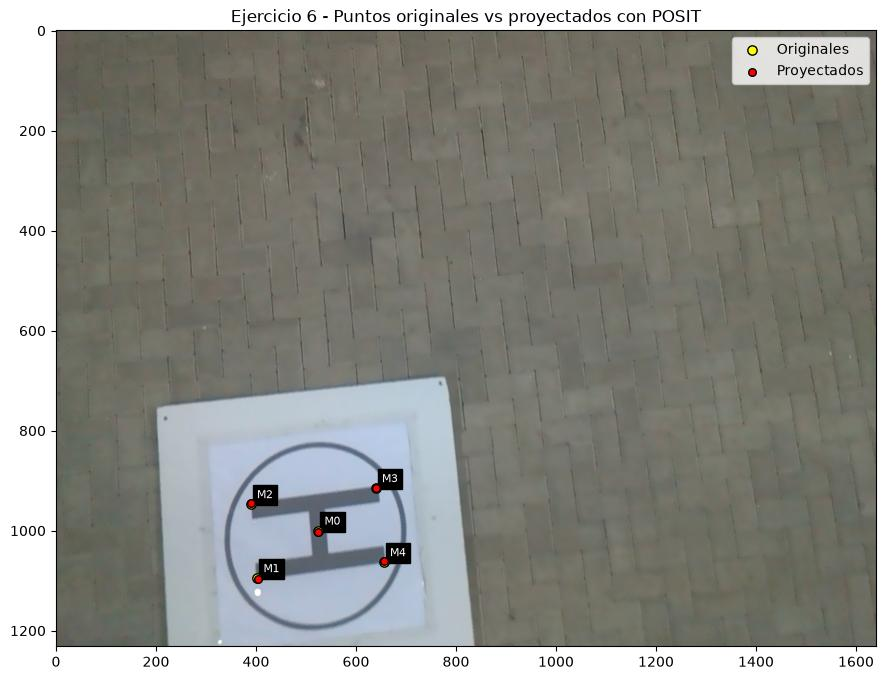

In [164]:
mostrar_puntos(img_heli, puntos_2d, etiquetas_heli, puntos_proyectados,
               'Ejercicio 6 - Puntos originales vs proyectados con POSIT')

**f) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda).**

Para que la cámara observe la letra H de manera vertical, debemos determinar una nueva matriz de rotación $R$.
Como los puntos de la H pertenecen al plano $UV$, dado que todos tienen $W=0$, el eje óptico de la cámara debe ser perpendicular a dicho plano.
Además, tenemos que considerar el punto blanco, que señala la esquina superior izquierda de la H y nos ayuda a determinar cómo debe quedar orientada la imagen.
La matriz de rotación se construye a partir de los vectores unitarios y mutuamente ortogonales $i$, $j$ y $k$, que forman una base ortonormal (BON):

$$
R=\begin{pmatrix}
i^T\\
j^T\\
k^T
\end{pmatrix},
\qquad k=i\times j
$$

Para determinar la matriz de rotación, consideramos las coordenadas 3D de los puntos de H, en particular tendremos
en cuenta los puntos: 

$M_0=(0,0,0)$ (centro de la H) y $M_1=(-0.175,0.3,0)$ (punto más cercano al punto blanco en la esquina superior izquierda de la H)

En la foto original, $M_1$ aparece a la izquierda y debajo de $M_0$, ya que sus coordenadas 2D son:

$$
m_0=(525,1000),\qquad m_1=(403,1095)
$$


Para la nueva pose queremos que $M_1$ aparezca arriba a la izquierda de $M_0$.
Partiendo de la siguiente ecuación:

$$
\begin{pmatrix}
X\\
Y\\
Z
\end{pmatrix}
=
R
\begin{pmatrix}
U\\
V\\
W
\end{pmatrix}
+t
$$

Como las coordenadas de la imagen aumentan hacia la derecha y hacia abajo, buscamos que $M_1$ tenga $X_1<0$ e $Y_1<0$ en el sistema de la nueva cámara, tomando como referencia el centro $M_0$.

Entonces, si tomamos

$$
i=(1,0,0)
$$

para que la dirección horizontal positiva de $U$ se proyecte hacia la derecha, y así logramos que $M_1$, que tiene $U_1<0$, aparezca a la izquierda.

También elegimos:

$$
j=(0,-1,0)
$$

porque queremos que $M_1$, cuya coordenada $V_1=0.3$ es positiva, aparezca por encima de $M_0$ en la imagen. Como la coordenada vertical de la imagen aumenta hacia abajo, necesitamos que su coordenada $Y_1$ respecto de la cámara sea negativa.

Como queremos que $M_0$ quede sobre el eje óptico, tomamos $t_x=t_y=0$. Entonces:

$$
X=U,\qquad Y=-V
$$

Finalmente, calculamos:

$$
k=i\times j=(0,0,-1)
$$

Este vector es perpendicular al plano $UV$ y apunta hacia abajo, suponiendo que el eje $W$ positivo apunta hacia arriba.

Por lo tanto, la matriz de rotación que nos sirve es:

$$
R=
\begin{pmatrix}
1&0&0\\
0&-1&0\\
0&0&-1
\end{pmatrix}
$$

Y esta matriz cumple las condiciones de una matriz de rotación:

$$
R^TR=I,\qquad \det(R)=1
$$

Respecto al vector de traslación t, si buscamos ubicar el dron exactamente sobre el centro de la H, queremos que $M_0$ quede sobre el eje óptico de la cámara, a una profundidad $h>0$ , que representaría la altura a la que se encunetra el dron.

Utilizamos la ecuación:

$$
RM_0+t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix}
$$

Como $M_0=(0,0,0)$, obtenemos:

$$
t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix}
$$


Finalmente, la pose de la cámara que cumple las condiciones está dada por:

$$
\boxed{
R=
\begin{pmatrix}
1&0&0\\
0&-1&0\\
0&0&-1
\end{pmatrix},
\qquad
t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix},
\quad h>0
}
$$



**Verificación** 

Tomamos como altura $h$ la profundidad que estimó POSIT en el inciso e) ($t_z$) y proyectamos los 5 puntos de la H con la nueva pose. Si la pose es correcta, $M_0$ tiene que caer en el punto principal $(u_0, v_0)$ de $\mathbf{K}$ y las 4 esquinas tienen que formar un rectángulo alineado con los ejes de la imagen, con $M_1$ arriba a la izquierda:

In [165]:
R_f = np.array([[1.0, 0.0, 0.0],
                [0.0, -1.0, 0.0],
                [0.0, 0.0, -1.0]])
h = t[2]
t_f = np.array([0.0, 0.0, h])

print('det(R_f) =', alc.determinante_3x3(R_f))
print(f'R_f^T R_f =\n{alc.multiplicar(alc.traspuesta(R_f), R_f)}\n')
print(f'(u0, v0) = ({matriz_K[0, 2]}, {matriz_K[1, 2]})')

puntos_f = alc.proyectarPuntosUVW(puntos_3d, matriz_K, R_f, t_f)
for i in range(puntos_f.shape[0]):
    print(f'{etiquetas_heli[i]}: (u, v) = ({puntos_f[i, 0]:.1f}, {puntos_f[i, 1]:.1f})')

det(R_f) = 1.0
R_f^T R_f =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

(u0, v0) = (819.5, 615.5)
M0: (u, v) = (819.5, 615.5)
M1: (u, v) = (746.4, 489.0)
M2: (u, v) = (892.6, 489.0)
M3: (u, v) = (892.6, 742.0)
M4: (u, v) = (746.4, 742.0)


Proyectamos los puntos con la nueva pose (R_f, t_f) sobre la foto original para ver donde cae

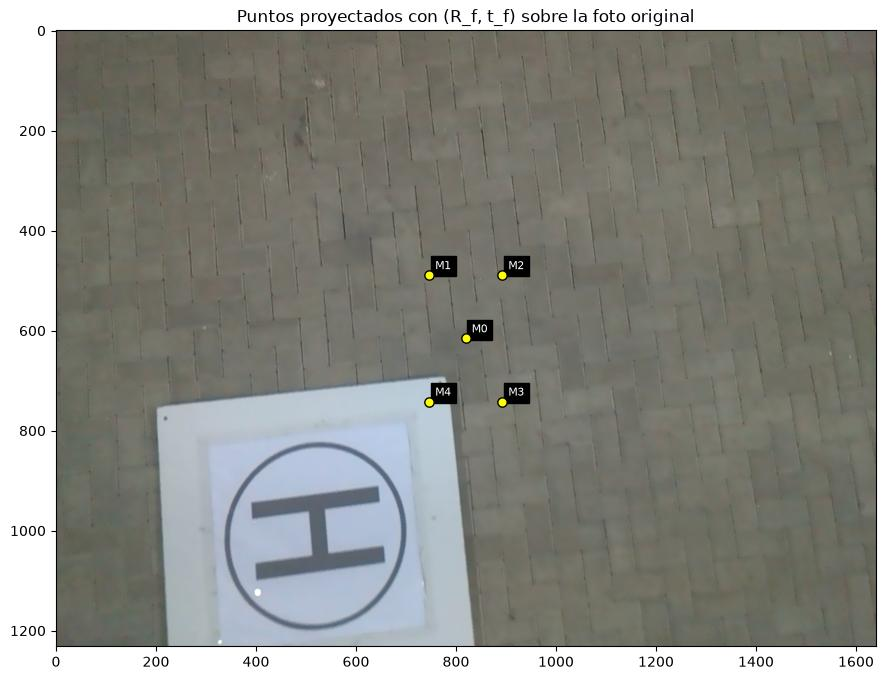

In [166]:
mostrar_puntos(img_heli, puntos_f, etiquetas_heli, titulo='Puntos proyectados con (R_f, t_f) sobre la foto original')